# Projet Data Mining - Analyse des données publiques

## 1. Introduction

Nous étudions les neuf fichiers de `public_records` pour rechercher des liens entre les personnes, les organisations et les événements. Le rapport suit le nettoyage, les analyses, puis les croisements avec la santé et la logistique. Les données et le narratif sont fictifs.


In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

racine = Path.cwd()
if not (racine / "data/public_records").is_dir():
    racine = racine.parent
if not (racine / "data/public_records").is_dir():
    raise FileNotFoundError("Ouvrir le notebook depuis la racine du projet ou le dossier autre projet.")
dossier = racine / "data/public_records"

fichiers = [
    "institutional_memos",
    "licensed_facilities",
    "licensed_professionals",
    "officer_filings",
    "public_and_investigative_documents",
    "public_appointments",
    "registered_entities",
    "regulatory_case_events",
    "site_access_case_events"
]

donnees = {}

for fichier in fichiers:
    donnees[fichier] = pd.read_csv(dossier / f"{fichier}.csv")

print("Nombre de fichiers chargés :", len(donnees))


Nombre de fichiers chargés : 9


## 2. Exploration générale des données

Nous regardons les dimensions et les colonnes des neuf fichiers pour repérer ce qu'ils contiennent.


In [2]:
resume = []
for nom, df in donnees.items():
    resume.append({
        "Fichier": nom,
        "Lignes": len(df),
        "Colonnes": len(df.columns),
        "Doublons exacts": df.duplicated().sum(),
        "Valeurs manquantes": df.isna().sum().sum()
    })
resume_df = pd.DataFrame(resume)
display(resume_df)


,Fichier,Lignes,Colonnes,Doublons exacts,Valeurs manquantes
0,institutional_memos,30,12,0,67
1,licensed_facilities,3,12,0,3
2,licensed_professionals,53,10,0,79
3,officer_filings,136,12,1,77
4,public_and_investigative_documents,40,11,0,1
5,public_appointments,62,12,0,77
6,registered_entities,24,10,0,24
7,regulatory_case_events,233,16,1,482
8,site_access_case_events,413,15,1,67


### 2.1. Dictionnaire des données

Nous sélectionnons les lignes du dictionnaire correspondant aux neuf fichiers publics. Elles donnent le sens des colonnes, leur type et les identifiants utilisables pour les jointures.


In [3]:
dictionnaire = pd.read_csv(racine / "data/data_dictionary.csv")
dico_public = dictionnaire[dictionnaire["file_name"].isin([f + ".csv" for f in fichiers])]
cles = dico_public[dico_public["key_role"].notna() & (dico_public["key_role"] != "non_key")]
display(cles[["file_name", "field_name", "logical_type"]])


,file_name,field_name,logical_type
50,licensed_facilities.csv,facility_license_number,identifier
62,licensed_professionals.csv,license_number,identifier
72,officer_filings.csv,filing_id,identifier
84,public_appointments.csv,appointment_record_id,identifier
96,registered_entities.csv,registration_number,identifier
167,regulatory_case_events.csv,regulatory_event_id,identifier
183,site_access_case_events.csv,access_event_id,identifier
332,institutional_memos.csv,document_id,identifier
344,public_and_investigative_documents.csv,document_id,identifier


## 3. Nettoyage des données

Les contrôles portent sur les doublons, les absences, les identifiants et les formats.
Les données brutes restent dans `donnees` ; nous travaillons sur `donnees_clean`.

### 3.1. Doublons exacts

Le bilan initial signale trois doublons exacts, que nous retirons de la copie.


In [4]:
donnees_clean = {
    nom: df.drop_duplicates().reset_index(drop=True).copy()
    for nom, df in donnees.items()
}


### 3.2. Harmoniser les espaces

Nous retirons les espaces superflus dans toutes les colonnes textuelles, notamment les noms des personnes. Les paragraphes des documents sont conservés. La même fonction servira aux tables chargées pour les croisements.

Pour les dates ajoutées plus loin, nous lisons d'abord le format ISO, puis les autres formats avec la convention jour/mois/année. Une date renseignée illisible arrête le calcul.


In [5]:
def nettoyer_espaces(table):
    table = table.copy()
    for col in table.select_dtypes(include=["object", "string"]):
        motif = r"[ \t]+" if col == "text" else r"\s+"
        table[col] = table[col].str.replace(motif, " ", regex=True).str.strip()
    return table


def convertir_dates(serie):
    dates = pd.to_datetime(serie, format="ISO8601", errors="coerce")
    dates = dates.fillna(pd.to_datetime(serie, format="mixed", dayfirst=True, errors="coerce"))
    if (serie.notna() & dates.isna()).any():
        raise ValueError("Une date renseignée ne peut pas être lue.")
    return dates


for nom, table in donnees_clean.items():
    donnees_clean[nom] = nettoyer_espaces(table)


### 3.3. Vérification des identifiants

Nous contrôlons les identifiants après retrait des doublons exacts. Si un identifiant se répète avec des informations différentes, les lignes doivent être examinées avant toute suppression.


In [6]:
bilan_cles = []
for nom, df in donnees_clean.items():
    cles_fichier = cles.loc[cles["file_name"].eq(f"{nom}.csv"), "field_name"]
    for colonne in cles_fichier:
        bilan_cles.append({
            "Fichier": nom,
            "Identifiant": colonne,
            "Absents": df[colonne].isna().sum(),
            "Doublons": df[colonne].dropna().duplicated().sum()
        })
display(pd.DataFrame(bilan_cles))


,Fichier,Identifiant,Absents,Doublons
0,institutional_memos,document_id,0,0
1,licensed_facilities,facility_license_number,0,0
2,licensed_professionals,license_number,0,0
3,officer_filings,filing_id,0,0
4,public_and_investigative_documents,document_id,0,0
5,public_appointments,appointment_record_id,0,0
6,registered_entities,registration_number,0,0
7,regulatory_case_events,regulatory_event_id,0,0
8,site_access_case_events,access_event_id,0,0


### Résultats de la vérification des doublons

Trois doublons exacts ont été retirés : un dans `officer_filings`, un dans `regulatory_case_events` et un dans `site_access_case_events`. Les identifiants contrôlés sont ensuite uniques.

### 3.4. Analyse des valeurs manquantes

Nous comptons les absences par colonne et les rapportons au nombre de lignes du fichier.


In [7]:
bilan_absences = []
for nom, df in donnees_clean.items():
    for colonne, nombre in df.isna().sum().items():
        if nombre > 0:
            bilan_absences.append({
                "Fichier": nom, "Colonne": colonne,
                "Absents": nombre, "Pourcentage": round(100 * nombre / len(df), 1)
            })
display(pd.DataFrame(bilan_absences))


,Fichier,Colonne,Absents,Pourcentage
0,institutional_memos,related_purchase_order,25,83.3
1,institutional_memos,related_shipment_number,22,73.3
2,institutional_memos,related_case_number,20,66.7
3,licensed_facilities,license_end,3,100.0
4,licensed_professionals,license_expiry_date,53,100.0
5,licensed_professionals,primary_facility_license,26,49.1
6,officer_filings,cessation_date,77,57.0
7,public_and_investigative_documents,author_name,1,2.5
8,public_appointments,recorded_birth_year,9,14.5
9,public_appointments,appointment_end,34,54.8


### Interprétation des valeurs manquantes

Les colonnes `license_end`, `license_expiry_date` et `parent_registration_number` sont entièrement vides. Nous les écartons des tables d'analyse ; elles restent disponibles dans les données brutes.

Les autres absences sont conservées. Par exemple, une date de fin de fonction manquante peut correspondre à un mandat encore en cours.


In [8]:
colonnes_vides = {
    "registered_entities": "parent_registration_number",
    "licensed_facilities": "license_end",
    "licensed_professionals": "license_expiry_date"
}
for nom, colonne in colonnes_vides.items():
    donnees_clean[nom] = donnees_clean[nom].drop(columns=colonne)


### 3.5. Formats et conversion des dates

Le dictionnaire indique les colonnes temporelles. Nous repérons d'abord les écritures
qui ne se lisent pas directement au format ISO.


In [9]:
colonnes_dates = dico_public[dico_public["logical_type"] == "date_or_datetime"]

dates_a_verifier = []
for _, ligne in colonnes_dates.iterrows():
    nom = ligne["file_name"].replace(".csv", "")
    col = ligne["field_name"]
    if col not in donnees_clean[nom]:
        continue
    dates = donnees_clean[nom][col]
    lecture_iso = pd.to_datetime(dates, format="ISO8601", errors="coerce")
    for valeur in dates[dates.notna() & lecture_iso.isna()].unique():
        dates_a_verifier.append({"Fichier": nom, "Colonne": col, "Valeur": valeur})
display(pd.DataFrame(dates_a_verifier))


,Fichier,Colonne,Valeur
0,licensed_professionals,license_issue_date,01/07/1994
1,public_appointments,appointment_start,01/01/1974
2,regulatory_case_events,event_time,08-Jun-2022 10:00:00
3,site_access_case_events,event_time,22-Sep-2023 09:00:00
4,site_access_case_events,event_time,10-Feb-2017 09:00:00


Cinq dates demandent une autre lecture. La fonction `convertir_dates` lit d'abord le
format ISO, puis les formats mixtes avec la convention jour/mois/année.
Elle vérifie qu'aucune date renseignée ne devient manquante.

Nous appliquons cette conversion à toutes les colonnes temporelles conservées.


In [10]:
nombre_colonnes_dates = 0
for _, ligne in colonnes_dates.iterrows():
    nom = ligne["file_name"].replace(".csv", "")
    col = ligne["field_name"]
    if col in donnees_clean[nom]:
        donnees_clean[nom][col] = convertir_dates(donnees_clean[nom][col])
        nombre_colonnes_dates += 1
print(nombre_colonnes_dates, "colonnes temporelles converties, aucune date renseignée perdue.")


13 colonnes temporelles converties, aucune date renseignée perdue.


### 3.6. Cohérence des dates de mandat


In [11]:
# Sélection du fichier officer_filings
df = donnees_clean["officer_filings"]

# Recherche des dates de fin antérieures aux dates de début
anomalies = df[df["cessation_date"] < df["appointment_date"]]

print("Nombre de périodes incohérentes :", len(anomalies))

display(anomalies[["full_name", "appointment_date", "cessation_date"]])

Nombre de périodes incohérentes : 9


,full_name,appointment_date,cessation_date
35,Calen Uren,2007-01-01,2006-12-31
49,Liora Corda,2014-01-01,2012-12-31
76,Jalen Quorin,2013-01-01,2011-12-31
83,Orin Norel,1998-01-01,1997-12-31
99,Pavel Waren,2011-01-01,2010-12-31
123,Elian Cevan,2025-01-01,2024-12-31
126,Daria Garen,2000-01-01,1998-12-31
128,Uma Wessen,2015-01-01,2014-12-31
130,Petra Koral,2005-01-01,2004-12-31


Dans `officer_filings`, neuf dates de cessation précèdent la nomination. Nous gardons ces lignes pour les signaler, puis les excluons des calculs de durées atypiques.


In [12]:
df = donnees_clean["public_appointments"]
incoherentes = df[df["appointment_end"] < df["appointment_start"]]
print("Nominations publiques avec une fin avant le début :", len(incoherentes))


Nominations publiques avec une fin avant le début : 0


Dans `public_appointments`, aucune date de fin ne précède le début du mandat.

### 3.7. Variables catégorielles

Après le nettoyage des espaces, nous vérifions les variantes de casse des activités
dans les deux journaux d'événements.


In [13]:
variantes = []
for nom in ["regulatory_case_events", "site_access_case_events"]:
    for valeur, nombre in donnees_clean[nom]["activity"].value_counts().items():
        if valeur != valeur.lower():
            variantes.append({"Fichier": nom, "Activité": valeur, "Nombre": nombre})
display(pd.DataFrame(variantes))


,Fichier,Activité,Nombre
0,regulatory_case_events,Technical_Review,1
1,regulatory_case_events,Triage_Review,1
2,site_access_case_events,REQUEST_SUBMITTED,2
3,site_access_case_events,ACCESS_COMPLETED,1


Les espaces ont déjà été harmonisés. Nous mettons maintenant les activités en minuscules pour regrouper, par exemple, `Technical_Review` et `technical_review`.


In [14]:
for nom in ["regulatory_case_events", "site_access_case_events"]:
    donnees_clean[nom]["activity"] = donnees_clean[nom]["activity"].str.lower()

print("technical_review :", donnees_clean["regulatory_case_events"]["activity"].eq("technical_review").sum())
print("triage_review :", donnees_clean["regulatory_case_events"]["activity"].eq("triage_review").sum())
print("wildlife_review :", donnees_clean["site_access_case_events"]["activity"].eq("wildlife_review").sum())


technical_review : 23
triage_review : 40
wildlife_review : 46


Les mêmes activités sont maintenant regroupées : 23 `technical_review` et 40 `triage_review` dans les dossiers réglementaires ; 63 `request_submitted` et 54 `access_completed` dans les accès aux sites.

### 3.8. Vérification des valeurs numériques

Les colonnes actuellement numériques sont les coordonnées des établissements et `recorded_birth_year`. Les années ou tranches de naissance de `officer_filings` sont encore stockées comme du texte. Nous commençons par les coordonnées et les années déjà numériques.


In [15]:
# Vérification des coordonnées géographiques 
df = donnees_clean["licensed_facilities"]

anomalies_geo = df[
    (~df["latitude"].between(-90, 90)) |
    (~df["longitude"].between(-180, 180))
]

print("Nombre de coordonnées aberrantes :", len(anomalies_geo))
display(anomalies_geo)

# Vérification des années de naissance a

df = donnees_clean["public_appointments"]

print(df["recorded_birth_year"].describe())

anomalies_naissance = df[
    (df["recorded_birth_year"] > 2026) |
    (df["recorded_birth_year"] < 1900)
]

print("Nombre d'années aberrantes :", len(anomalies_naissance))
display(anomalies_naissance)


Nombre de coordonnées aberrantes : 0


,facility_license_number,facility_name,facility_category,operating_organization_registration,street_address,region,latitude,longitude,license_start,facility_status,declared_services


count      53.000000
mean     1968.075472
std        15.077810
min      1935.000000
25%      1960.000000
50%      1970.000000
75%      1978.000000
max      1993.000000
Name: recorded_birth_year, dtype: float64
Nombre d'années aberrantes : 0


,appointment_record_id,appointing_jurisdiction,office_holder_name,recorded_birth_year,office_title,institution_name,appointment_start,appointment_end,appointment_basis,departure_reason,official_region,source_notice_reference


Les coordonnées respectent les bornes de latitude et de longitude. Les 53 années de naissance renseignées vont de 1935 à 1993, avec une médiane de 1970.

### 3.9. Âge approximatif lors de la nomination


In [16]:
df = donnees_clean["public_appointments"].copy()
df["age_nomination"] = df["appointment_start"].dt.year - df["recorded_birth_year"]
anomalies_age = df[(df["age_nomination"] < 18) | (df["age_nomination"] > 100)]
print("Âges à la nomination hors de l'intervalle 18–100 ans :", len(anomalies_age))
if not anomalies_age.empty:
    display(anomalies_age[["office_holder_name", "recorded_birth_year", "age_nomination"]])


Âges à la nomination hors de l'intervalle 18–100 ans : 0


Les âges approximatifs renseignés restent entre 18 et 100 ans. Les dates de fin ont
déjà été contrôlées dans la section sur les mandats.

## 4. Statistiques descriptives

Nous représentons quatre répartitions utiles pour l'enquête. Les autres fichiers
sont résumés dans le texte et analysés dans les sections suivantes.


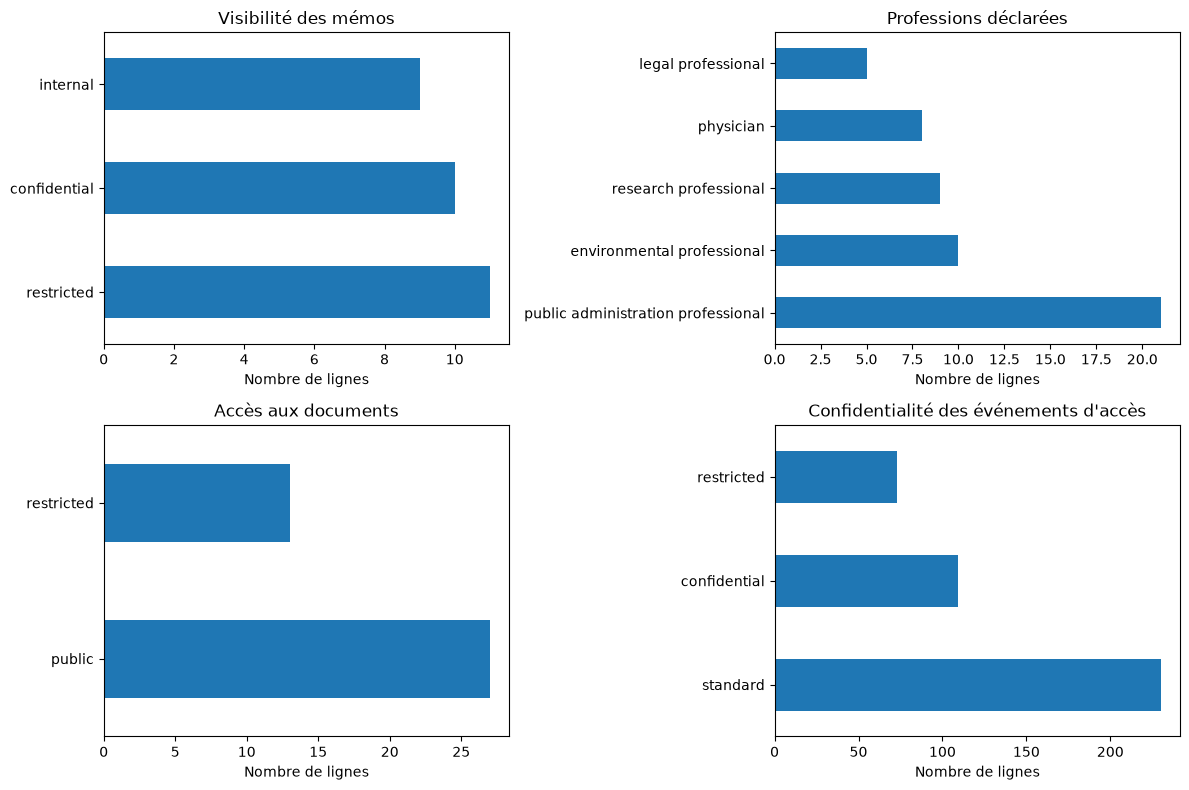

In [17]:
repartitions = [
    ("institutional_memos", "visibility_level", "Visibilité des mémos"),
    ("licensed_professionals", "profession", "Professions déclarées"),
    ("public_and_investigative_documents", "public_or_restricted", "Accès aux documents"),
    ("site_access_case_events", "confidentiality_class", "Confidentialité des événements d'accès")
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (nom, colonne, titre) in zip(axes.flat, repartitions):
    donnees_clean[nom][colonne].value_counts().plot.barh(ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("Nombre de lignes")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


### 4.1. Interprétation des statistiques descriptives

- Les 30 mémos couvrent six types de documents, avec cinq mémos par type. Leur visibilité se répartit entre 11 restreints, 10 confidentiels et 9 internes.
- Les trois établissements sont un hôpital de recherche, une clinique privée et un laboratoire. Parmi les 53 professionnels, 21 relèvent de l'administration publique et 50 n'ont pas d'antécédent disciplinaire enregistré.
- Les 135 mandats de sociétés comprennent 77 enregistrements actifs et 58 historiques. Parmi les 24 organisations, 18 sont actives.
- Les documents publics ou d'investigation sont au nombre de 40 : 27 publics et 13 restreints.
- Dans les nominations publiques, 34 motifs de départ manquent ; 24 correspondent à une transition de fonction. La médiane des années de naissance renseignées est de 1970.
- Les plaintes environnementales représentent 73 événements réglementaires, les inspections de cargaison 44 et celles liées à la faune 35.
- Les événements d'accès aux sites se répartissent entre 230 `standard`, 109 `confidential` et 73 `restricted`.

Ces derniers effectifs comptent des événements, pas des dossiers : une même demande peut apparaître plusieurs fois.

### 4.2. Analyse des corrélations

Pearson et Spearman portent sur des variables numériques. Une corrélation entre coordonnées et années de naissance ne répondrait pas à notre question. Nous privilégions ici les tableaux croisés, les dates et les relations entre organisations.

## 5. Ordonner et regrouper les données

Nous comparons les demandes d'accès aux sites pour repérer des dossiers qui se ressemblent. Il faut d'abord passer d'une ligne par événement à une ligne par dossier.

### 5.1. Passer des événements aux dossiers

Les 412 événements concernent 60 dossiers. Nous vérifions que les caractéristiques
restent constantes dans chaque dossier avant de les regrouper.


In [18]:
df = donnees_clean["site_access_case_events"].copy()
print(len(df), "événements pour", df["access_case_number"].nunique(), "dossiers.")

colonnes = [
    "site_code", "requesting_organization_name", "requesting_registration_number",
    "authorizing_agency", "access_purpose", "equipment_category", "confidentiality_class"
]
variations = df.groupby("access_case_number")[colonnes].nunique(dropna=False)
print("Dossiers avec une caractéristique qui varie :", variations.gt(1).any(axis=1).sum())


412 événements pour 60 dossiers.
Dossiers avec une caractéristique qui varie : 0


Le site, l'organisation, l'agence, le motif, l'équipement et la confidentialité sont constants dans chaque dossier. Nous pouvons donc conserver leur première valeur lors du regroupement. Le nombre d'étapes varie, jusqu'à dix pour `ACC-2023-0013`.

### 5.2. Une ligne par dossier


In [19]:
# Regrouper les événements par dossier

df_dossiers = (
    df.sort_values("event_time")
      .groupby("access_case_number", as_index=False)
      .agg(
          site_code=("site_code", "first"),
          requesting_organization_name=("requesting_organization_name", "first"),
          requesting_registration_number=("requesting_registration_number", "first"),
          authorizing_agency=("authorizing_agency", "first"),
          access_purpose=("access_purpose", "first"),
          equipment_category=("equipment_category", "first"),
          confidentiality_class=("confidentiality_class", "first"),
          nombre_evenements=("access_event_id", "count"),
          date_debut=("event_time", "min"),
          date_fin=("event_time", "max")
      )
)

print("Dimensions :", df_dossiers.shape)


Dimensions : (60, 11)


La table comporte maintenant 60 lignes et 11 colonnes. Chaque dossier est décrit par ses caractéristiques, son nombre d'événements et ses dates de début et de fin.

### 5.3. Variables retenues

Le site, le motif, l'équipement et la confidentialité décrivent les dossiers.
L'organisation sert à interpréter les groupes, sans participer au calcul des distances.

### 5.4. Distance de Hamming

Cette distance est la proportion des quatre caractéristiques qui diffèrent entre
deux dossiers. Elle vaut 0 si elles sont identiques et 1 si elles diffèrent toutes.
Chaque caractéristique a le même poids.


In [20]:
from scipy.spatial.distance import pdist, squareform

variables_clustering = ["site_code", "access_purpose", "equipment_category", "confidentiality_class"]
X = df_dossiers[variables_clustering].copy()
X_codes = X.apply(lambda col: col.astype("category").cat.codes)
distances = squareform(pdist(X_codes.to_numpy(), metric="hamming"))
matrice_distances = pd.DataFrame(
    distances, index=df_dossiers["access_case_number"], columns=df_dossiers["access_case_number"]
)


Les catégories sont remplacées par des codes pour permettre le calcul. Hamming teste seulement l'égalité des codes : il n'utilise ni leur ordre ni l'écart numérique entre eux.

### 5.5. Visualisation des distances

La carte représente les 60 dossiers dans l'ordre de `df_dossiers`. Les petites
valeurs indiquent des demandes proches sur les quatre caractéristiques retenues.


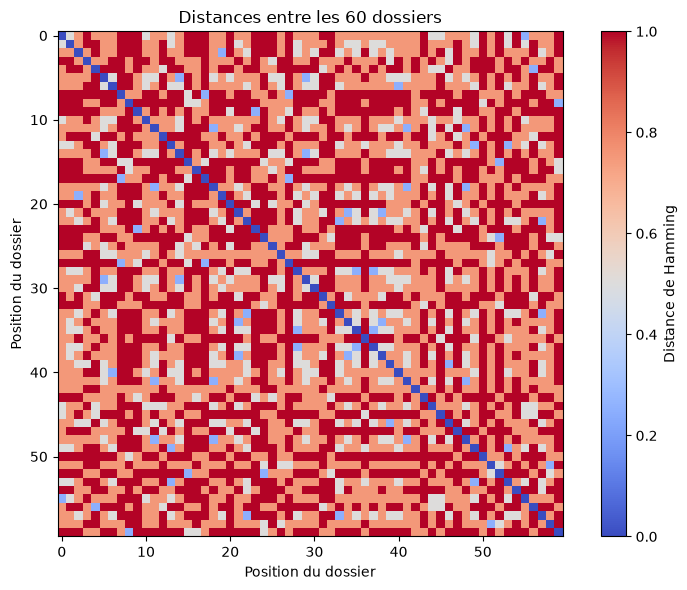

In [21]:
plt.figure(figsize=(8, 6))
plt.imshow(matrice_distances, cmap="coolwarm", vmin=0, vmax=1)
plt.colorbar(label="Distance de Hamming")
plt.xlabel("Position du dossier")
plt.ylabel("Position du dossier")
plt.title("Distances entre les 60 dossiers")
plt.tight_layout()
plt.show()


### 5.6. Classification hiérarchique

Nous utilisons la liaison moyenne (`average`) : la distance entre deux groupes
est la moyenne des distances entre leurs dossiers.


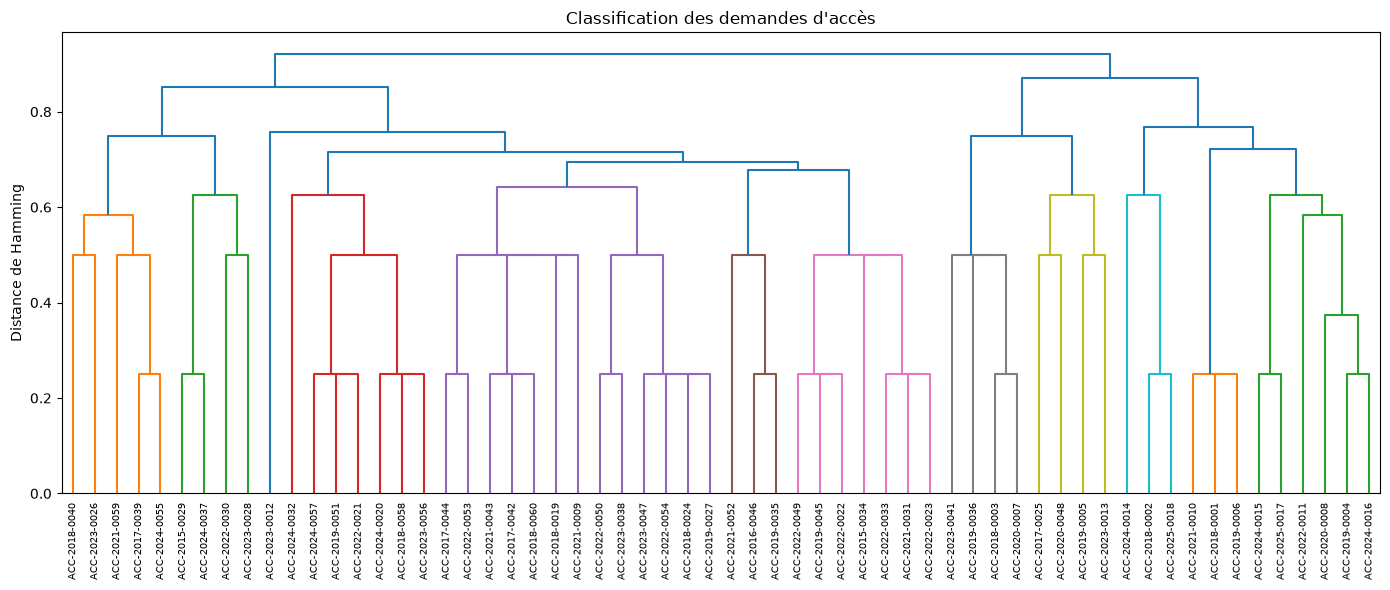

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(pdist(X_codes.to_numpy(), metric="hamming"), method="average")
plt.figure(figsize=(14, 6))
dendrogram(Z, labels=df_dossiers["access_case_number"].values, leaf_rotation=90, leaf_font_size=7)
plt.title("Classification des demandes d'accès")
plt.ylabel("Distance de Hamming")
plt.tight_layout()
plt.show()


Des dossiers proches fusionnent dès la hauteur 0,25. Les groupes plus différents se rejoignent plus haut dans le dendrogramme.


In [23]:
bilan_coupures = []
for seuil in [0.5, 0.6, 0.7, 0.8]:
    groupes = pd.Series(fcluster(Z, t=seuil, criterion="distance")).value_counts()
    bilan_coupures.append({
        "Seuil": seuil, "Groupes": len(groupes),
        "Plus petit": groupes.min(), "Plus grand": groupes.max()
    })
display(pd.DataFrame(bilan_coupures))


,Seuil,Groupes,Plus petit,Plus grand
0,0.5,20,1,7
1,0.6,18,1,7
2,0.7,10,1,23
3,0.8,4,8,31


Les seuils 0,5, 0,6, 0,7 et 0,8 donnent 20, 18, 10 et 4 groupes. Nous retenons
**0,7** pour garder dix groupes lisibles. Le plus grand compte 23 dossiers et le
plus petit un seul.

Ce choix reste exploratoire. La hauteur de fusion en liaison moyenne ne garantit
pas que toutes les paires d'un groupe soient à moins de 0,7.


In [24]:
# Attribuer un cluster à chaque dossier
df_dossiers["cluster"] = fcluster(Z, t=0.7, criterion="distance")

# Examiner les niveaux de confidentialité par cluster
tableau = pd.crosstab(
    df_dossiers["cluster"],
    df_dossiers["confidentiality_class"]
)

display(tableau)

repartition_horizon = df_dossiers[
    df_dossiers["requesting_organization_name"].eq("Horizon Field Research Cooperative")
]["confidentiality_class"].value_counts()
display(repartition_horizon)


confidentiality_class,confidential,restricted,standard
cluster,,,
1,3,1,1
2,2,0,2
3,0,1,6
4,0,0,23
5,0,0,1
6,0,4,0
7,4,0,0
8,2,1,0
9,0,3,0


confidentiality_class
confidential    8
restricted      6
standard        4
Name: count, dtype: int64

### Interprétation des résultats

Horizon compte 18 dossiers : 8 confidentiels, 6 restreints et 4 standards. Cette répartition aide à lire les groupes. La confidentialité ayant servi au clustering, la retrouver dans leurs caractéristiques n'est pas une vérification indépendante.

## 6. Recherche de patterns et d'anomalies

### 6.1. Préparer les caractéristiques des dossiers


In [25]:
dossiers_cm4 = df_dossiers[
    ["access_case_number", "access_purpose", "equipment_category", "confidentiality_class"]
].copy()


### 6.2. Matrice de cooccurrences

Nous croisons le motif d'accès et la confidentialité, avec une seule ligne par dossier. Les pourcentages sont calculés à l'intérieur de chaque motif.


In [26]:
# Matrice de cooccurrences
matrice = pd.crosstab(
    dossiers_cm4["access_purpose"],
    dossiers_cm4["confidentiality_class"]
)

display(matrice)

# Calcul des pourcentages par ligne
matrice_pct = matrice.div(matrice.sum(axis=1), axis=0) * 100

display(matrice_pct.round(1))


confidentiality_class,confidential,restricted,standard
access_purpose,,,
acoustic monitoring and equipment maintenance,3,3,3
emergency equipment recovery,3,2,4
habitat restoration assessment,1,1,8
habitat survey and sample documentation,2,2,1
night wildlife monitoring programme,3,1,0
orchard pollination survey,0,0,3
routine monitoring visit,2,1,9
sensor maintenance,1,0,7


confidentiality_class,confidential,restricted,standard
access_purpose,,,
acoustic monitoring and equipment maintenance,33.3,33.3,33.3
emergency equipment recovery,33.3,22.2,44.4
habitat restoration assessment,10.0,10.0,80.0
habitat survey and sample documentation,40.0,40.0,20.0
night wildlife monitoring programme,75.0,25.0,0.0
orchard pollination survey,0.0,0.0,100.0
routine monitoring visit,16.7,8.3,75.0
sensor maintenance,12.5,0.0,87.5


### Interprétation des résultats

Les quatre dossiers de surveillance nocturne sont confidentiels (75 %) ou restreints (25 %). Pour la documentation d'échantillons, ces deux catégories représentent 80 % des dossiers. Les visites de surveillance habituelles sont, elles, standards à 75 %. Les petits effectifs restent visibles dans le tableau des comptes.

### 6.3. Analyse des dossiers de surveillance nocturne

Nous regardons les organisations et les sites des dossiers déclarés comme `night wildlife monitoring programme`.


In [27]:
# Sélectionner les dossiers de surveillance nocturne
df = donnees_clean["site_access_case_events"]

dossiers = df[
    df["access_purpose"] == "night wildlife monitoring programme"
]

# Conserver une ligne par dossier
dossiers = dossiers.drop_duplicates(subset="access_case_number")

# Afficher les informations
display(dossiers[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "confidentiality_class"
]])

,access_case_number,requesting_organization_name,site_code,confidentiality_class
8,ACC-2018-0002,Horizon Field Research Cooperative,KNT-KES,confidential
31,ACC-2019-0005,Horizon Field Research Cooperative,KNT-LUM,confidential
104,ACC-2024-0014,Horizon Field Research Cooperative,KNT-KES,restricted
136,ACC-2025-0018,Horizon Field Research Cooperative,AVL-ORR,confidential


### Interprétation des résultats

Les quatre dossiers de surveillance nocturne viennent d'Horizon et concernent trois sites. Kestrel apparaît deux fois, en 2018 et 2024. Les quatre demandes sont confidentielles ou restreintes.

### 6.4. Analyse des activités sur les sites identifiés

Nous reprenons les autres dossiers des mêmes sites pour voir si Horizon y intervient aussi avec d'autres motifs.


In [28]:
# Récupérer les sites identifiés précédemment
sites = dossiers["site_code"].unique()

# Conserver une ligne par dossier
df_sites = df.drop_duplicates(subset="access_case_number")

# Sélectionner les dossiers associés à ces sites
resultats = df_sites[df_sites["site_code"].isin(sites)]

display(resultats[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "access_purpose",
    "confidentiality_class"
]].sort_values("site_code"))

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
54,ACC-2020-0008,Horizon Field Research Cooperative,AVL-ORR,acoustic monitoring and equipment maintenance,confidential
136,ACC-2025-0018,Horizon Field Research Cooperative,AVL-ORR,night wildlife monitoring programme,confidential
8,ACC-2018-0002,Horizon Field Research Cooperative,KNT-KES,night wildlife monitoring programme,confidential
62,ACC-2021-0009,Horizon Field Research Cooperative,KNT-KES,acoustic monitoring and equipment maintenance,standard
104,ACC-2024-0014,Horizon Field Research Cooperative,KNT-KES,night wildlife monitoring programme,restricted
31,ACC-2019-0005,Horizon Field Research Cooperative,KNT-LUM,night wildlife monitoring programme,confidential
86,ACC-2023-0012,Horizon Field Research Cooperative,KNT-LUM,habitat survey and sample documentation,standard


### Interprétation des résultats

Les sept dossiers retrouvés sur ces sites viennent tous d'Horizon. La surveillance nocturne y côtoie la maintenance acoustique et la documentation d'échantillons.

### 6.5. Détection d'anomalies

Nous cherchons les dossiers dont le nombre d'étapes est éloigné des autres. Nous commençons par compter les événements de chaque demande.


In [29]:
# Compter le nombre d'événements par dossier
nb_evenements = donnees_clean["site_access_case_events"].groupby(
    "access_case_number"
).size()

# Statistiques descriptives
print(nb_evenements.describe())

# Répartition du nombre d'événements
print(nb_evenements.value_counts().sort_index())

# Calcul de l'IQR
Q1 = nb_evenements.quantile(0.25)
Q3 = nb_evenements.quantile(0.75)

IQR = Q3 - Q1

# Calcul des bornes
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Recherche des valeurs aberrantes
anomalies = nb_evenements[
    (nb_evenements < borne_inf) |
    (nb_evenements > borne_sup)
]

print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)
print("Nombre de dossiers atypiques :", len(anomalies))


count    60.000000
mean      6.866667
std       1.111827
min       4.000000
25%       6.000000
50%       7.000000
75%       7.000000
max      10.000000
dtype: float64
4      2
5      4
6     12
7     28
8     11
9      2
10     1
Name: count, dtype: int64
Borne inférieure : 4.5
Borne supérieure : 8.5
Nombre de dossiers atypiques : 5


### Interprétation des résultats

L'IQR signale cinq dossiers sur 60 : deux comportent quatre événements et trois en comportent neuf ou dix. La médiane est de sept événements.


In [30]:
# Sélectionner les dossiers atypiques
df = donnees_clean["site_access_case_events"]

dossiers_atypiques = df[
    df["access_case_number"].isin(anomalies.index)
]

# Conserver une ligne par dossier
dossiers_atypiques = dossiers_atypiques.drop_duplicates(
    subset="access_case_number"
)

# Afficher les caractéristiques
display(dossiers_atypiques[[
    "access_case_number",
    "requesting_organization_name",
    "site_code",
    "access_purpose",
    "confidentiality_class"
]])

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
70,ACC-2021-0010,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,restricted
94,ACC-2023-0013,Horizon Field Research Cooperative,AVL-VEL,habitat survey and sample documentation,confidential
111,ACC-2024-0015,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,standard
144,ACC-2018-0019,Interregional Procurement Cooperative,KNT-CYP,emergency equipment recovery,standard
278,ACC-2018-0040,Dune Agricultural Machinery,AVL-ARU,emergency equipment recovery,restricted


### Interprétation des dossiers atypiques

Les trois dossiers longs concernent Horizon. Les deux dossiers courts portent sur la récupération d'équipements d'urgence.

### 6.5.1. Analyse des dossiers atypiques

Nous lisons les activités dans l'ordre des dates pour comprendre ces différences de longueur.


In [31]:
evenements_atypiques = donnees_clean["site_access_case_events"]
evenements_atypiques = evenements_atypiques[
    evenements_atypiques["access_case_number"].isin(anomalies.index)
].sort_values(["access_case_number", "event_time"])
for dossier, groupe in evenements_atypiques.groupby("access_case_number"):
    print(dossier, ":", " → ".join(groupe["activity"]))


ACC-2018-0019 : request_submitted → technical_review → authorization_denied → closure_recorded
ACC-2018-0040 : request_submitted → technical_review → authorization_denied → closure_recorded
ACC-2021-0010 : request_submitted → technical_review → wildlife_review → authorization_denied → request_submitted → authorization_granted → access_started → access_completed → closure_recorded
ACC-2023-0013 : request_submitted → technical_review → wildlife_review → security_review → authorization_denied → request_submitted → authorization_granted → access_started → access_completed → closure_recorded
ACC-2024-0015 : request_submitted → technical_review → wildlife_review → authorization_denied → request_submitted → authorization_granted → access_started → access_completed → closure_recorded


### Interprétation des résultats

Les deux dossiers courts suivent quatre étapes : demande, examen technique, refus puis clôture. Les trois dossiers longs comportent un refus suivi d'une nouvelle demande et d'une autorisation. `ACC-2023-0013` a aussi un examen de sécurité supplémentaire. Le parcours explique donc leur signalement par l'IQR.

### 6.6. Recherche d'anomalies dans les durées de fonction des dirigeants

Nous examinons ensuite les durées de mandat dans `officer_filings`, pour rechercher des fonctions particulièrement longues ou courtes.

### 6.6.1. Calcul des durées de fonction

Le calcul porte sur les mandats terminés, dont les dates de nomination et de cessation sont connues. Les mandats encore ouverts n'ont pas de durée définitive et sont étudiés séparément des mandats terminés.


In [32]:
df_dirigeants = donnees_clean["officer_filings"].copy()
mandats_termines = df_dirigeants.dropna(subset=["appointment_date", "cessation_date"]).copy()
mandats_termines["duree_annees"] = (
    mandats_termines["cessation_date"] - mandats_termines["appointment_date"]
).dt.days / 365.25
print("Mandats terminés :", len(mandats_termines))
display(mandats_termines["duree_annees"].describe())


Mandats terminés : 58


count    58.000000
mean     11.365102
std      12.014370
min      -1.004791
25%       3.997262
50%       8.996578
75%      11.747433
max      48.999316
Name: duree_annees, dtype: float64

### Interprétation des durées de fonction

Les 58 mandats terminés ont une médiane d'environ neuf ans et une moyenne de 11,37 ans. Ceux d'Edward Vann et d'Emil Warden approchent 49 ans. Neuf durées sont négatives et demandent un traitement séparé.


In [33]:
mandats_incoherents = mandats_termines[mandats_termines["duree_annees"] < 0]
print("Durées négatives, déjà repérées au nettoyage :", len(mandats_incoherents))


Durées négatives, déjà repérées au nettoyage : 9


### Vérification des incohérences chronologiques

Six écarts négatifs sont d'un jour et trois d'environ un an. Nous gardons ces lignes dans les données, mais les excluons de la recherche de durées atypiques. Le calcul suivant porte ainsi sur 49 mandats aux dates cohérentes.

### 6.6.2. Détection des durées de fonction atypiques avec le Z-score modifié

Le z-score modifié compare chaque durée à la médiane, avec la MAD, c'est-à-dire la médiane des écarts absolus à cette médiane. Le calcul est `0,6745 × (durée − médiane) / MAD`.

Nous utilisons le seuil de 3,5 en valeur absolue pour signaler les durées éloignées. La médiane et la MAD sont moins sensibles aux valeurs extrêmes que la moyenne et l'écart-type.


In [34]:
mandats_valides = mandats_termines[mandats_termines["duree_annees"] >= 0].copy()
mediane = mandats_valides["duree_annees"].median()
mad = np.median(np.abs(mandats_valides["duree_annees"] - mediane))
print("Mandats valides :", len(mandats_valides), "— médiane :", mediane, "— MAD :", mad)

if mad > 0:
    mandats_valides["z_score_modifie"] = 0.6745 * (mandats_valides["duree_annees"] - mediane) / mad
    anomalies_dirigeants = mandats_valides[mandats_valides["z_score_modifie"].abs() > 3.5]
    print("Mandats atypiques :", len(anomalies_dirigeants))
else:
    raise ValueError("MAD nulle : le z-score modifié ne peut pas être calculé.")


Mandats valides : 49 — médiane : 9.995893223819301 — MAD : 3.997262149212868
Mandats atypiques : 6


### Interprétation des résultats du Z-score modifié

Sur les 49 mandats valides, la médiane est de dix ans et la MAD de quatre ans. Six durées dépassent le seuil : elles vont de 34 à 49 ans. Edward Vann et Emil Warden ont les durées les plus longues, suivis d'Adrian Vosmere et de Jonah Bell.

### 6.6.3. Identification des organisations associées aux mandats atypiques

La jointure par `registration_number` retrouve les organisations des six mandats signalés.


In [35]:
# Informations sur les organisations
organisations = donnees_clean["registered_entities"][
    ["registration_number", "legal_name", "declared_activity"]
].drop_duplicates(subset="registration_number")

# Jointure avec les mandats atypiques
anomalies_organisations = anomalies_dirigeants.merge(
    organisations,
    on="registration_number",
    how="left",
    validate="many_to_one"
)

# Afficher les résultats
display(
    anomalies_organisations[
        [
            "full_name",
            "legal_name",
            "declared_activity",
            "duree_annees",
            "z_score_modifie"
        ]
    ].sort_values("duree_annees", ascending=False)
)

,full_name,legal_name,declared_activity,duree_annees,z_score_modifie
0,Edward Vann,Vann Maritime Advisory,Industrial and shipping advisory practice,48.999316,6.581457
1,Emil Warden,Warden Medical Ventures,Commercial and medical investment partnership,48.993840,6.580533
2,Adrian Vosmere,Vosmere Biotechnics,Biotechnology and transport company,39.997262,5.062446
4,Jonah Bell,Bell Conservation Survey,Regional conservation survey,39.997262,5.062446
5,Julien Marot,Marot Ecological Policy Office,Environmental-policy advisory office,34.997947,4.218859
3,J. Varlan,Varlan Natural History Circle,Natural-history correspondence society,33.993155,4.049310


### Interprétation des organisations associées aux mandats atypiques

Ces organisations interviennent dans le transport, la biotechnologie, l'investissement médical, la conservation et le conseil environnemental. Nous examinons ensuite leurs dirigeants communs pour rechercher des liens administratifs entre elles.

## 7. Analyse des graphes et des processus 

### 7.1. Préparation des événements

Nous trions les événements de chaque dossier par date. Une transition relie deux activités consécutives dans le même dossier.


In [36]:
journal = donnees_clean["site_access_case_events"][["access_case_number", "event_time", "activity"]].copy()
journal = journal.sort_values(["access_case_number", "event_time"])


### 7.2. Analyse des transitions entre les activités

Nous comptons chaque couple « activité → activité suivante » pour distinguer les parcours fréquents et les variantes.


In [37]:
journal["activite_suivante"] = journal.groupby("access_case_number")["activity"].shift(-1)
transitions = journal.groupby(["activity", "activite_suivante"]).size().reset_index(name="nombre")
transitions = transitions.sort_values("nombre", ascending=False)


### 7.3. Visualisation des transitions entre les activités

Le graphe est orienté : les nœuds sont les activités et les flèches suivent leur enchaînement. Le poids d'une flèche est son nombre d'occurrences.


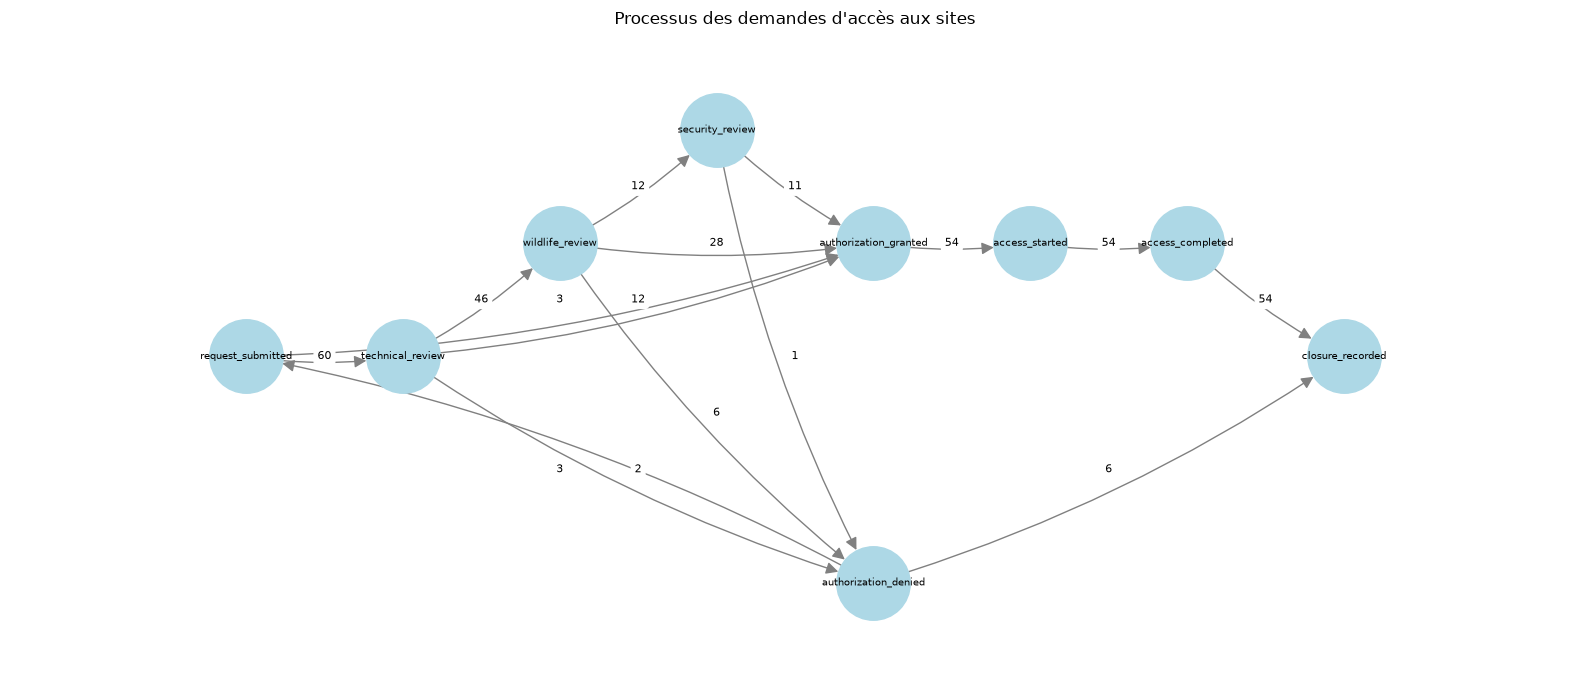

In [38]:
import networkx as nx

G = nx.DiGraph()
for _, ligne in transitions.iterrows():
    G.add_edge(ligne["activity"], ligne["activite_suivante"], weight=ligne["nombre"])

# Les mêmes positions permettent de comparer les deux versions du processus.
positions_processus = {
    "request_submitted": (0, 0), "technical_review": (2, 0),
    "wildlife_review": (4, 1), "security_review": (6, 2),
    "authorization_granted": (8, 1), "access_started": (10, 1),
    "access_completed": (12, 1), "authorization_denied": (8, -2),
    "closure_recorded": (14, 0)
}

def afficher_processus(graphe, titre):
    plt.figure(figsize=(16, 7))
    nx.draw_networkx(
        graphe, positions_processus, node_color="lightblue", node_size=2800,
        font_size=7, arrowsize=18, edge_color="gray", connectionstyle="arc3,rad=0.08"
    )
    nx.draw_networkx_edge_labels(
        graphe, positions_processus, edge_labels=nx.get_edge_attributes(graphe, "weight"),
        font_size=8, rotate=False
    )
    plt.title(titre)
    plt.margins(0.15)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

afficher_processus(G, "Processus des demandes d'accès aux sites")


Le parcours principal va de la demande à la clôture, en passant par les examens et l'autorisation. Les variantes comprennent des examens de sécurité et des refus suivis de nouvelles demandes.

### 7.4. Analyse des dépendances entre les activités — Heuristic Miner

Nous reprenons le principe du Heuristic Miner vu dans le cours sur les graphes et les processus. Pour deux activités A et B, le score est `(nombre A→B − nombre B→A) / (nombre A→B + nombre B→A + 1)`.

Un score élevé indique un enchaînement surtout observé dans le sens A→B. Ce score n'est pas une probabilité de transition.


In [39]:
# Calcul des scores de dépendance du Heuristic Miner

dependances = []

for a, b, data in G.edges(data=True):

    freq_ab = data["weight"]

    # Fréquence de la transition inverse
    freq_ba = G[b][a]["weight"] if G.has_edge(b, a) else 0

    score = (freq_ab - freq_ba) / (freq_ab + freq_ba + 1)

    dependances.append({
        "activite_depart": a,
        "activite_arrivee": b,
        "frequence": freq_ab,
        "dependance": round(score, 3)
    })

df_dependances = pd.DataFrame(dependances)

df_dependances = df_dependances.sort_values(
    "dependance",
    ascending=False
)


`request_submitted → technical_review` apparaît 60 fois, avec un score de 0,984. La transition `authorization_denied → request_submitted` apparaît trois fois, avec un score de 0,750.


In [40]:
transitions_fortes = df_dependances[df_dependances["dependance"] >= 0.90]
print("Transitions conservées :", len(transitions_fortes))
display(transitions_fortes)


Transitions conservées : 9


,activite_depart,activite_arrivee,frequence,dependance
0,request_submitted,technical_review,60,0.984
5,access_started,access_completed,54,0.982
6,access_completed,closure_recorded,54,0.982
7,authorization_granted,access_started,54,0.982
2,technical_review,wildlife_review,46,0.979
8,wildlife_review,authorization_granted,28,0.966
3,technical_review,authorization_granted,12,0.923
9,wildlife_review,security_review,12,0.923
11,security_review,authorization_granted,11,0.917


### 7.5. Visualisation du processus simplifié

Nous gardons les dépendances d'au moins **0,90** pour dessiner le parcours principal.
Sans transition inverse, il faut au moins neuf occurrences pour atteindre ce score.
Ce filtre conserve neuf des quinze transitions ; les six variantes sont examinées ensuite.


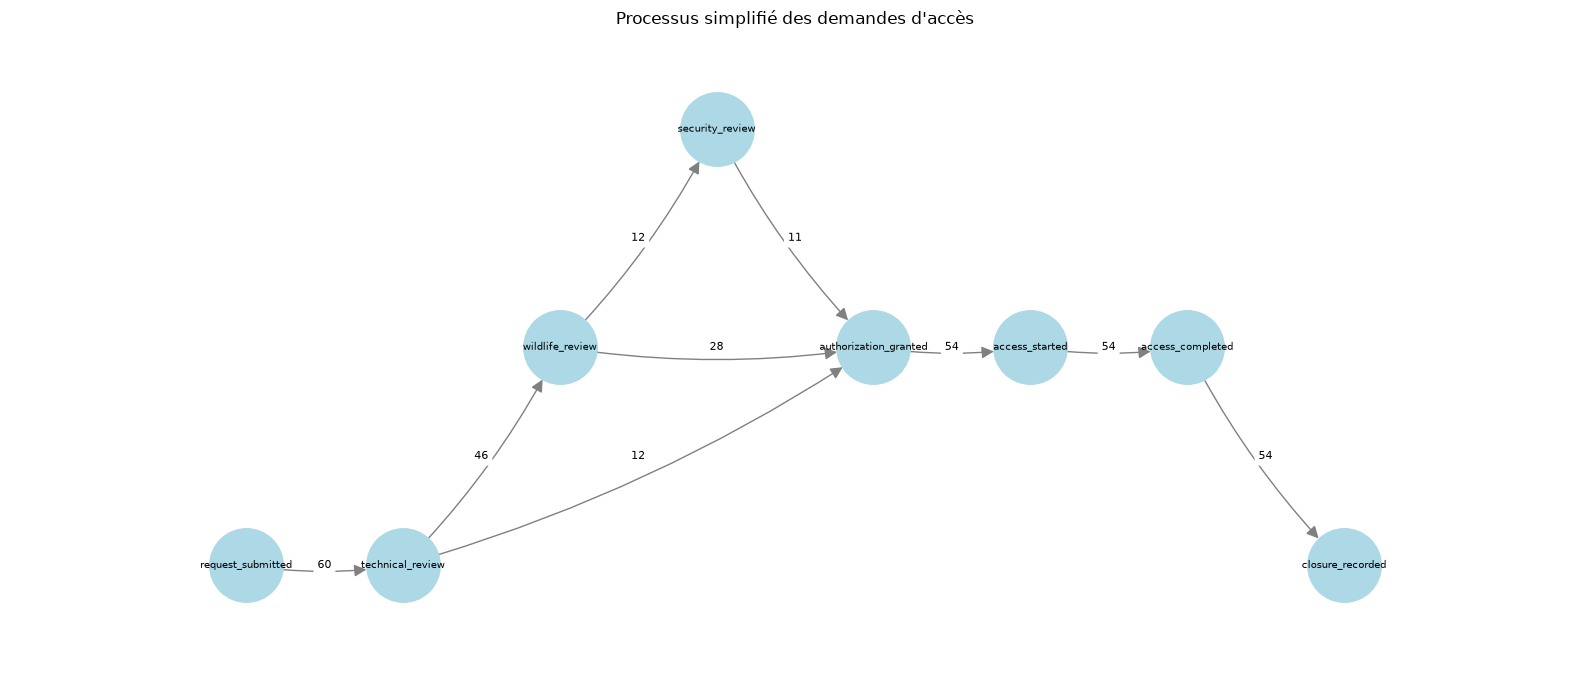

In [41]:
G_filtre = nx.DiGraph()
for _, ligne in transitions_fortes.iterrows():
    G_filtre.add_edge(ligne["activite_depart"], ligne["activite_arrivee"], weight=ligne["frequence"])
afficher_processus(G_filtre, "Processus simplifié des demandes d'accès")


Le graphe réduit montre les examens, l'autorisation et le déroulement des 54 accès autorisés. Les refus et les nouvelles soumissions sont moins visibles après filtrage ; nous les examinons avec les transitions écartées.

### 7.6. Analyse des transitions moins fréquentes

Nous reprenons les six transitions écartées du dessin pour identifier les variantes du parcours.


In [42]:
transitions_exclues = df_dependances[df_dependances["dependance"] < 0.90]
display(transitions_exclues)


,activite_depart,activite_arrivee,frequence,dependance
10,wildlife_review,authorization_denied,6,0.857
13,authorization_denied,closure_recorded,6,0.857
14,authorization_denied,request_submitted,3,0.750
1,request_submitted,authorization_granted,3,0.750
4,technical_review,authorization_denied,2,0.667
12,security_review,authorization_denied,1,0.500


Six passages vont de `wildlife_review` à `authorization_denied`, et trois d'un refus à une nouvelle soumission. Nous retrouvons les dossiers concernés.


In [43]:
# Identifier les dossiers contenant un refus suivi d'une nouvelle soumission

df_access = donnees_clean["site_access_case_events"].copy()

df_access = df_access.sort_values(
    ["access_case_number", "event_time", "access_event_id"]
)

df_access["activite_suivante"] = (
    df_access.groupby("access_case_number")["activity"].shift(-1)
)

dossiers_resoumis = df_access[
    (df_access["activity"] == "authorization_denied") &
    (df_access["activite_suivante"] == "request_submitted")
]

display(
    dossiers_resoumis[
        [
            "access_case_number",
            "requesting_organization_name",
            "site_code",
            "access_purpose",
            "confidentiality_class"
        ]
    ]
)

,access_case_number,requesting_organization_name,site_code,access_purpose,confidentiality_class
73,ACC-2021-0010,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,restricted
98,ACC-2023-0013,Horizon Field Research Cooperative,AVL-VEL,habitat survey and sample documentation,confidential
114,ACC-2024-0015,Horizon Field Research Cooperative,AVL-MAR,acoustic monitoring and equipment maintenance,standard


Les refus suivis d'une nouvelle demande concernent `ACC-2021-0010`, `ACC-2023-0013` et `ACC-2024-0015`, tous déposés par Horizon. Deux portent sur `AVL-MAR` et un sur `AVL-VEL`. Ce sont aussi les trois dossiers longs signalés par l'IQR.


In [44]:
dossiers = dossiers_resoumis["access_case_number"].tolist()
parcours = df_access[df_access["access_case_number"].isin(dossiers)]
delais_parcours = []
for dossier, groupe in parcours.groupby("access_case_number"):
    refus = groupe.loc[groupe["activity"].eq("authorization_denied"), "event_time"].iloc[0]
    nouvelle = groupe.loc[groupe["activity"].eq("request_submitted") & groupe["event_time"].gt(refus), "event_time"].min()
    autorisation = groupe.loc[groupe["activity"].eq("authorization_granted"), "event_time"].min()
    delais_parcours.append({
        "Dossier": dossier,
        "Refus → nouvelle demande (jours)": (nouvelle - refus).total_seconds() / 86400,
        "Nouvelle demande → autorisation (jours)": (autorisation - nouvelle).total_seconds() / 86400
    })
display(pd.DataFrame(delais_parcours).round(2))


,Dossier,Refus → nouvelle demande (jours),Nouvelle demande → autorisation (jours)
0,ACC-2021-0010,2.0,2.0
1,ACC-2023-0013,2.0,2.0
2,ACC-2024-0015,2.0,2.0


#### Analyse des parcours après refus

Dans les trois dossiers, une nouvelle demande est déposée deux jours après le refus, puis autorisée deux jours plus tard. L'accès commence dix jours après l'autorisation et se déroule de 18 h à 3 h. Nous comparons ces horaires à ceux des autres dossiers.


In [45]:
# Horaires de début des accès pour tous les dossiers

debut_acces = df_access[
    df_access["activity"] == "access_started"
].copy()

debut_acces["heure_debut"] = debut_acces["event_time"].dt.hour

print("Répartition des heures de début d'accès :")
display(debut_acces["heure_debut"].value_counts().sort_index())

Répartition des heures de début d'accès :


heure_debut
17    36
18    18
Name: count, dtype: int64

Sur les 54 accès réalisés, 36 commencent à 17 h et 18 à 18 h. Les trois dossiers étudiés commencent à 18 h, comme d'autres accès : cet horaire ne les distingue donc pas à lui seul.

### 7.6.1. Comparaison statistique des procédures d'accès - Test exact de Fisher

Nous comparons la présence d'un examen de sécurité chez Horizon et chez les autres organisations, avec une ligne par dossier. Le test exact de Fisher convient à cette table à deux lignes et deux colonnes, qui contient un effectif nul.


In [46]:
from scipy.stats import fisher_exact

# Une ligne par dossier d'accès
df_fisher = (
    donnees_clean["site_access_case_events"]
    .groupby("access_case_number")
    .agg(
        organisation=("requesting_organization_name", "first"),
        examen_securite=(
            "activity",
            lambda x: x.astype(str).str.strip().str.lower()
                       .eq("security_review").any()
        )
    )
    .reset_index()
)

# Identifier les dossiers de Horizon
df_fisher["horizon"] = (
    df_fisher["organisation"] == "Horizon Field Research Cooperative"
)

# Tableau de contingence
tableau_fisher = pd.crosstab(
    df_fisher["horizon"],
    df_fisher["examen_securite"]
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

tableau_fisher.index = ["Autres organisations", "Horizon"]
tableau_fisher.columns = ["Sans examen", "Avec examen"]

display(tableau_fisher)

# Test exact de Fisher
odds_ratio, p_value = fisher_exact(tableau_fisher.values)

print("Odds ratio :", odds_ratio)
print("p-value :", p_value)

,Sans examen,Avec examen
Autres organisations,42,0
Horizon,6,12


Odds ratio : inf
p-value : 1.3266075436377187e-08


### Interprétation du test exact de Fisher

Douze dossiers Horizon sur 18 ont un examen de sécurité (66,7 %), contre aucun des 42 autres. La p-value de Fisher est de 1,33 × 10⁻⁸ : la table indique une association entre l'organisation et cette étape.

L'odds ratio vaut `inf` parce qu'aucun dossier du groupe « autres » ne comporte d'examen de sécurité. Ce résultat vient du zéro dans la table ; il n'explique pas la raison de ces examens.

### 7.7. Analyse du réseau des dirigeants et des organisations

Nous recherchons les dirigeants présents dans plusieurs organisations à partir de `officer_filings`.


In [47]:
dirigeants_multiples = (
    df_dirigeants.groupby("full_name")["registration_number"].nunique()
    .reset_index(name="nombre_organisations")
)
verification_identites = (
    df_dirigeants[df_dirigeants["full_name"].isin(
        dirigeants_multiples.loc[dirigeants_multiples["nombre_organisations"] > 1, "full_name"]
    )].groupby("full_name").agg(
        nombre_identifiants=("officer_local_ref", "nunique"),
        nombre_organisations=("registration_number", "nunique")
    ).reset_index()
)
print("Dirigeants présents dans plusieurs organisations :", len(verification_identites))
print("Noms associés à plusieurs identifiants :", verification_identites["nombre_identifiants"].gt(1).sum())


Dirigeants présents dans plusieurs organisations : 27
Noms associés à plusieurs identifiants : 0


### Vérification des identifiants des dirigeants

Chaque nom correspond ici à un seul `officer_local_ref`, retrouvé dans deux organisations. Nous utilisons cet identifiant pour représenter une personne une seule fois.

### 7.8. Construction du graphe des relations entre dirigeants et organisations

Le graphe biparti contient deux types de nœuds : dirigeants et organisations. Un lien représente un mandat enregistré. Nous retenons les dirigeants multi-organisations ; le graphe décrit leurs fonctions connues, y compris lorsqu'elles ont eu lieu à des dates différentes.


In [48]:
ids_multiples = df_dirigeants.groupby("officer_local_ref")["registration_number"].nunique()
ids_multiples = ids_multiples[ids_multiples > 1].index
relations = df_dirigeants[df_dirigeants["officer_local_ref"].isin(ids_multiples)][
    ["officer_local_ref", "full_name", "registration_number"]
].drop_duplicates()

G_relations = nx.Graph()
for _, ligne in relations.iterrows():
    dirigeant = "DIR_" + str(ligne["officer_local_ref"])
    entreprise = "ENT_" + str(ligne["registration_number"])
    G_relations.add_node(dirigeant, type="dirigeant", label=ligne["full_name"])
    G_relations.add_node(entreprise, type="entreprise", label=ligne["registration_number"])
    G_relations.add_edge(dirigeant, entreprise)
print(G_relations.number_of_nodes(), "nœuds et", G_relations.number_of_edges(), "relations.")


39 nœuds et 54 relations.


### 7.9. Composantes et organisations du réseau

Une composante regroupe les nœuds reliés par un chemin. Nous comptons leurs
dirigeants et leurs organisations, puis identifions les sociétés concernées.


In [49]:
composantes = list(nx.connected_components(G_relations))
composantes_triees = sorted(composantes, key=len, reverse=True)
bilan_composantes = []
for i, composante in enumerate(composantes_triees, start=1):
    bilan_composantes.append({
        "Composante": i,
        "Dirigeants": sum(G_relations.nodes[n]["type"] == "dirigeant" for n in composante),
        "Organisations": sum(G_relations.nodes[n]["type"] == "entreprise" for n in composante)
    })
display(pd.DataFrame(bilan_composantes))

entreprises_composantes = []
for i, composante in enumerate(composantes_triees, start=1):
    numeros = [n.replace("ENT_", "", 1) for n in composante if G_relations.nodes[n]["type"] == "entreprise"]
    entreprises = donnees_clean["registered_entities"]
    entreprises = entreprises[entreprises["registration_number"].isin(numeros)]
    entreprises_composantes.append(entreprises[["legal_name", "declared_activity"]].assign(composante=i))
display(pd.concat(entreprises_composantes).sort_values(["composante", "legal_name"]))


,Composante,Dirigeants,Organisations
0,1,14,6
1,2,9,4
2,3,4,2


,legal_name,declared_activity,composante
22,Ardena Capital Union,Financial-services group,1
12,Horizon Field Research Cooperative,Environmental contractor,1
21,Nivren Maritime Logistics,Commercial maritime logistics company,1
2,Northstar Cold Chain Services,Refrigerated transport provider,1
6,Threshold Earth Observatory,Environmental research organization,1
3,Whitehaven Strategic Holdings,Investment and consulting company,1
11,Helix Legal and Compliance,Legal and regulatory consultancy,2
0,Meridian BioLogistics,International biological and cold-chain logistics,2
20,Solvane Energy Group,Energy and infrastructure company,2
4,Valenne Industrial Futures Council,Industry-policy association,2


### Interprétation des organisations présentes dans les composantes connexes

La première composante réunit notamment Horizon, Northstar Cold Chain Services, Nivren Maritime Logistics et Ardena Capital Union. La deuxième contient Meridian BioLogistics et Helix Legal and Compliance ; la troisième relie Meridian–Asterion Foundation et Common Ground Climate Forum.

Horizon partage donc des dirigeants avec des acteurs du transport et de la chaîne du froid. Le graphe fournit un lien administratif à rapprocher des dossiers d'accès.

### 7.10. Analyse de la centralité d'intermédiarité

La betweenness mesure la part des plus courts chemins passant par un nœud. Nous l'utilisons pour repérer les acteurs qui relient différentes parties du graphe.


In [50]:
# Calcul de la centralité d'intermédiarité
centralites = nx.betweenness_centrality(G_relations)

# Tableau des résultats
df_centralites = pd.DataFrame([
    {
        "noeud": n,
        "nom": G_relations.nodes[n]["label"],
        "type": G_relations.nodes[n]["type"],
        "centralite": score
    }
    for n, score in centralites.items()
])

# Les 10 nœuds les plus centraux
display(
    df_centralites.sort_values(
        "centralite", ascending=False
    ).head(10)
)


,noeud,nom,type,centralite
3,ENT_REG-NDH-01022,REG-NDH-01022,entreprise,0.123755
8,ENT_REG-VLN-01004,REG-VLN-01004,entreprise,0.123755
4,DIR_OFR-20022,Adrienne Solva,dirigeant,0.110953
2,DIR_OFR-20021,Oskar Nivren,dirigeant,0.110953
5,ENT_REG-VLN-01023,REG-VLN-01023,entreprise,0.103841
7,ENT_REG-TMB-01003,REG-TMB-01003,entreprise,0.103841
1,ENT_REG-VLN-01021,REG-VLN-01021,entreprise,0.054054
6,ENT_REG-VLN-01005,REG-VLN-01005,entreprise,0.054054
0,DIR_OFR-20020,Celene Varro,dirigeant,0.051209
20,DIR_OFR-20051,Nadia Aren,dirigeant,0.022760


### Interprétation de la centralité d'intermédiarité

Nivren Maritime Logistics et Whitehaven Strategic Holdings ont les scores les plus élevés (0,124), suivis d'Adrienne Solva et d'Oskar Nivren (0,111). Ardena Capital Union et Northstar atteignent 0,104. Ces acteurs appartiennent à la composante d'Horizon.

### 7.11. Visualisation du réseau principal

Nous affichons la plus grande composante, avec une couleur pour les dirigeants et une autre pour les organisations.


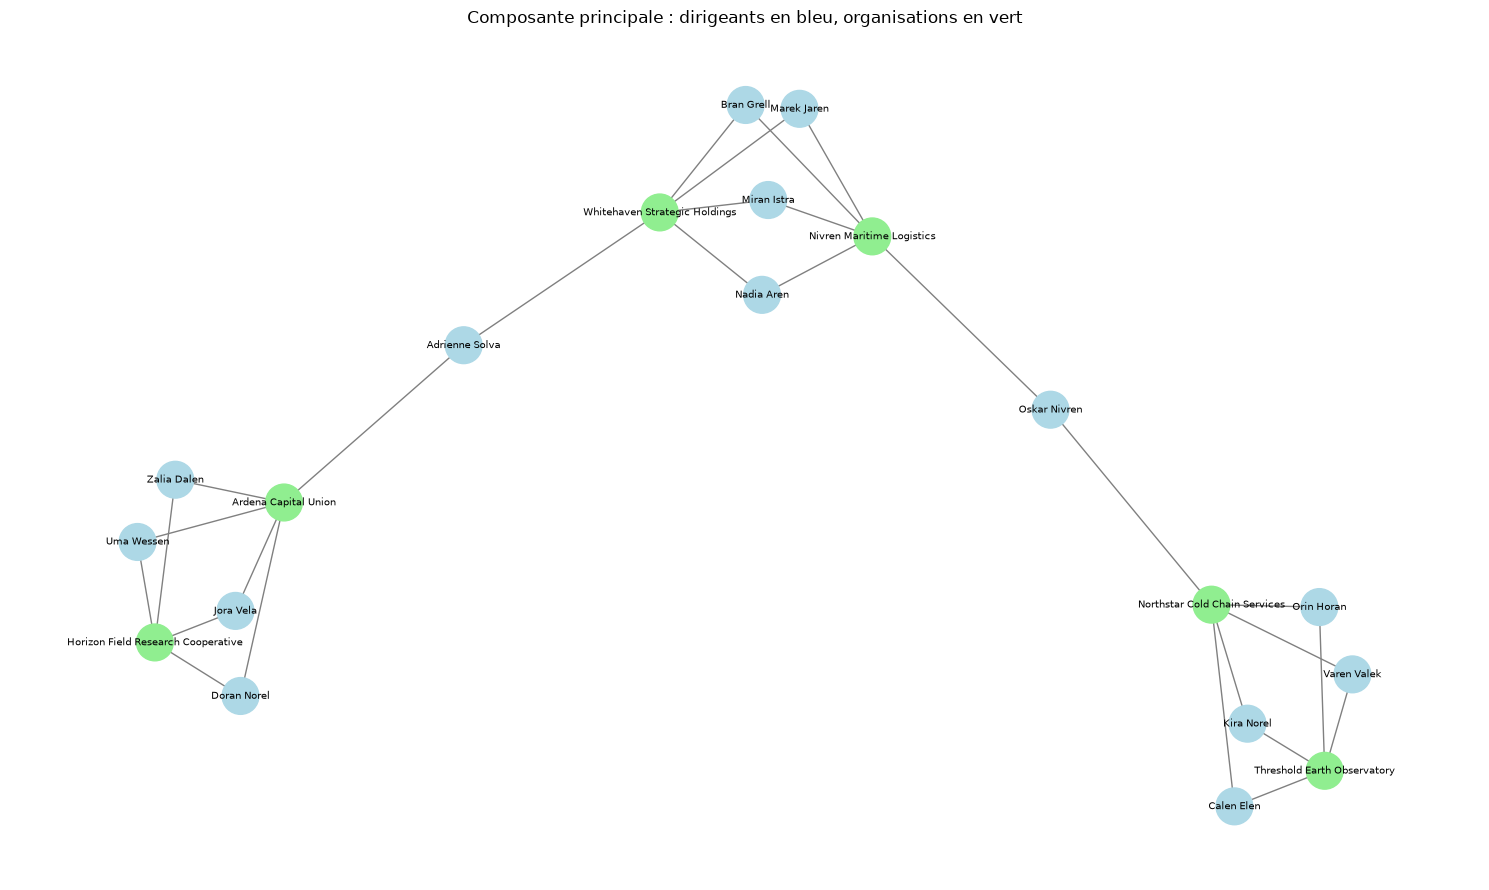

In [51]:
composante_principale = max(composantes, key=len)
G_principal = G_relations.subgraph(composante_principale).copy()
noms_entreprises = donnees_clean["registered_entities"].set_index("registration_number")["legal_name"].to_dict()
etiquettes = {}
for noeud, attributs in G_principal.nodes(data=True):
    numero = noeud.replace("ENT_", "", 1)
    etiquettes[noeud] = noms_entreprises[numero] if attributs["type"] == "entreprise" else attributs["label"]
couleurs = ["lightgreen" if G_principal.nodes[n]["type"] == "entreprise" else "lightblue" for n in G_principal]
plt.figure(figsize=(15, 9))
nx.draw_networkx(
    G_principal, nx.spring_layout(G_principal, seed=42), labels=etiquettes,
    node_color=couleurs, node_size=700, font_size=7, edge_color="gray"
)
plt.title("Composante principale : dirigeants en bleu, organisations en vert")
plt.axis("off")
plt.tight_layout()
plt.show()


### Interprétation du réseau principal

Les liens entre les 14 dirigeants et les six organisations rendent visibles les intermédiaires repérés par la centralité. Ils indiquent des mandats partagés entre entreprises, sans documenter leurs opérations logistiques.

## 8. Analyse des données spatiales et temporelles

Nous comptons les demandes par année de création, à partir des 60 dossiers. Chaque demande est comptée une seule fois.


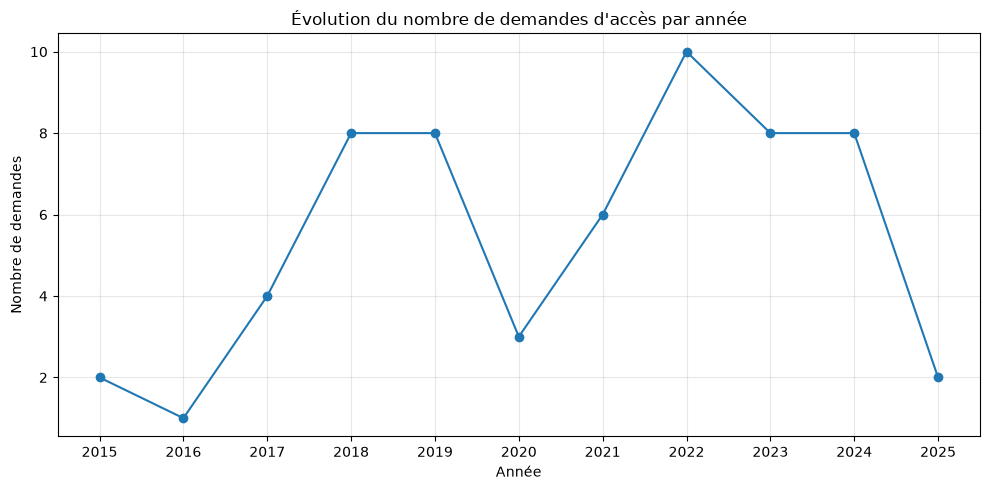

In [52]:
# Nombre de demandes d'accès par année

df_temporel = df_dossiers.copy()

df_temporel["annee"] = df_temporel["date_debut"].dt.year

demandes_par_annee = (
    df_temporel.groupby("annee")
    .size()
    .reset_index(name="nombre_demandes")
)



# Visualisation
plt.figure(figsize=(10, 5))

plt.plot(
    demandes_par_annee["annee"],
    demandes_par_annee["nombre_demandes"],
    marker="o"
)

plt.title("Évolution du nombre de demandes d'accès par année")
plt.xlabel("Année")
plt.ylabel("Nombre de demandes")
plt.xticks(demandes_par_annee["annee"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Interprétation de l'évolution temporelle

Le nombre de demandes varie de 2015 à 2025. Il n'y en a que trois en 2020, contre dix en 2022, puis huit en 2023 et huit en 2024. Nous regardons quelles organisations contribuent à ces variations.


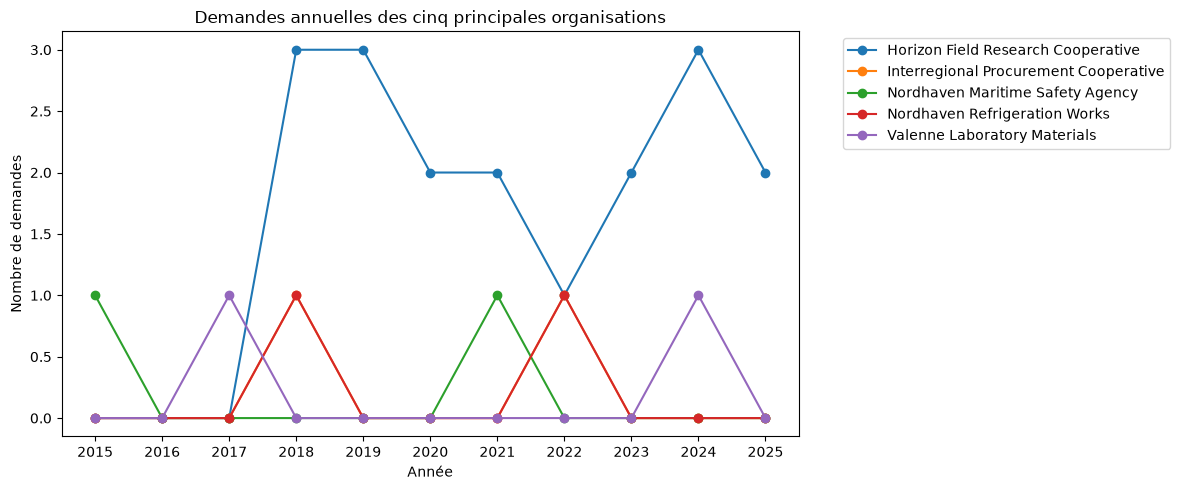

In [53]:
top_organisations = df_temporel["requesting_organization_name"].value_counts().head(5).index
demandes_organisations = df_temporel.groupby(
    ["annee", "requesting_organization_name"]
).size().reset_index(name="nombre_demandes")
evolution_organisations = demandes_organisations[
    demandes_organisations["requesting_organization_name"].isin(top_organisations)
]
tableau_evolution = evolution_organisations.pivot(
    index="annee", columns="requesting_organization_name", values="nombre_demandes"
).reindex(demandes_par_annee["annee"]).fillna(0)
tableau_evolution.plot(marker="o", figsize=(12, 5))
plt.title("Demandes annuelles des cinq principales organisations")
plt.xlabel("Année")
plt.ylabel("Nombre de demandes")
plt.xticks(tableau_evolution.index)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


Parmi les cinq organisations représentées, Horizon est la seule présente chaque année entre 2018 et 2025. Les autres apparaissent plus ponctuellement, généralement avec une seule demande par année.


In [54]:
# Nombre de demandes d'accès par site

demandes_par_site = (
    df_dossiers["site_code"]
    .value_counts()
    .reset_index()
)

demandes_par_site.columns = ["site_code", "nombre_demandes"]

print("Nombre de sites différents :", df_dossiers["site_code"].nunique())

display(demandes_par_site.head(10))


Nombre de sites différents : 50


,site_code,nombre_demandes
0,KNT-KES,3
1,AVL-MAR,3
2,TMB-NAC,2
3,TMB-PEL,2
4,KNT-LUM,2
5,AVL-VEL,2
6,KNT-SEN,2
7,AVL-ORR,2
8,KNT-DMJ,1
9,KNT-VXR,1


### Répartition des demandes d'accès par site

`KNT-KES` et `AVL-MAR` ont trois demandes chacun ; `AVL-VEL` en a deux. Les deux derniers sites sont aussi ceux des dossiers avec refus puis nouvelle soumission. Nous examinons leurs motifs d'accès.


In [55]:
# Examiner les dossiers associés aux sites les plus fréquents

sites_interessants = [
    "KNT-KES",
    "AVL-MAR",
    "AVL-VEL"
]

dossiers_sites = df_dossiers[
    df_dossiers["site_code"].isin(sites_interessants)
]

display(
    dossiers_sites[
        [
            "access_case_number",
            "site_code",
            "requesting_organization_name",
            "access_purpose",
            "equipment_category",
            "confidentiality_class"
        ]
    ].sort_values("site_code")
)

,access_case_number,site_code,requesting_organization_name,access_purpose,equipment_category,confidentiality_class
9,ACC-2018-0003,AVL-MAR,Horizon Field Research Cooperative,habitat survey and sample documentation,protective field equipment,restricted
27,ACC-2021-0010,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted
51,ACC-2024-0015,AVL-MAR,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,acoustic and camera equipment,standard
17,ACC-2019-0006,AVL-VEL,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted
43,ACC-2023-0013,AVL-VEL,Horizon Field Research Cooperative,habitat survey and sample documentation,protective field equipment,confidential
8,ACC-2018-0002,KNT-KES,Horizon Field Research Cooperative,night wildlife monitoring programme,portable monitoring and cold-storage equipment,confidential
26,ACC-2021-0009,KNT-KES,Horizon Field Research Cooperative,acoustic monitoring and equipment maintenance,protective field equipment,standard
50,ACC-2024-0014,KNT-KES,Horizon Field Research Cooperative,night wildlife monitoring programme,acoustic and camera equipment,restricted


### Analyse des sites les plus représentés

Les huit demandes de ces trois sites viennent d'Horizon. Elles concernent la surveillance acoustique, la maintenance, la documentation d'échantillons et la surveillance nocturne. Certains dossiers déclarent du matériel de stockage frigorifique.


In [56]:
# Comparaison des motifs d'accès selon les sites

tableau_sites_motifs = pd.crosstab(
    dossiers_sites["site_code"],
    dossiers_sites["access_purpose"]
)

display(tableau_sites_motifs)

access_purpose,acoustic monitoring and equipment maintenance,habitat survey and sample documentation,night wildlife monitoring programme
site_code,,,
AVL-MAR,2,1,0
AVL-VEL,1,1,0
KNT-KES,1,0,2


La surveillance acoustique et la maintenance apparaissent sur les trois sites. La documentation d'échantillons concerne `AVL-MAR` et `AVL-VEL`, tandis que le motif de surveillance nocturne se trouve ici à `KNT-KES`.


In [57]:
# Vérifier les informations géographiques disponibles
df_sites = donnees_clean["licensed_facilities"]

display(
    df_sites[
        ["facility_name", "latitude", "longitude"]
    ]
)

,facility_name,latitude,longitude
0,Asterion Central Clinical Campus,47.20,7.51
1,Asterion Avelora Executive Clinic,7.35,101.62
2,Threshold Earth Avelora Laboratory,7.50,101.75


### Limites de l'analyse spatiale

Les coordonnées de `licensed_facilities` concernent trois établissements médicaux, pas les sites naturels codés `KNT-…` ou `AVL-…` des demandes d'accès. Nous décrivons donc la répartition de ces demandes par site, sans leur attribuer ces coordonnées.

### Analyse temporelle des successions de dirigeants

Nous reprenons les dates des mandats pour examiner les périodes partagées et les successions de dirigeants.


In [58]:
# Préparer les mandats par organisation

successions = df_dirigeants[
    [
        "registration_number",
        "full_name",
        "appointment_date",
        "cessation_date"
    ]
].copy()

# Trier chronologiquement
successions = successions.sort_values(
    ["registration_number", "appointment_date"]
)

print("Nombre de mandats :", len(successions))


Nombre de mandats : 135


### Recherche de chevauchements entre les mandats

Nous comparons les périodes au sein d'une même organisation. Le calcul porte seulement sur les mandats terminés aux dates cohérentes ; ceux sans date de fin n'y entrent pas.


In [59]:
# Conserver uniquement les mandats terminés et cohérents
mandats_chrono = successions.dropna(
    subset=["appointment_date", "cessation_date"]
).copy()

mandats_chrono = mandats_chrono[
    mandats_chrono["cessation_date"] >= mandats_chrono["appointment_date"]
]

# Rechercher les paires de mandats qui se chevauchent
chevauchements = []

for entreprise, groupe in mandats_chrono.groupby("registration_number"):
    groupe = groupe.sort_values("appointment_date")

    for i in range(len(groupe)):
        for j in range(i + 1, len(groupe)):
            a = groupe.iloc[i]
            b = groupe.iloc[j]

            if b["appointment_date"] <= a["cessation_date"]:
                chevauchements.append({
                    "registration_number": entreprise,
                    "dirigeant_1": a["full_name"],
                    "dirigeant_2": b["full_name"],
                    "debut_1": a["appointment_date"],
                    "fin_1": a["cessation_date"],
                    "debut_2": b["appointment_date"],
                    "fin_2": b["cessation_date"]
                })

df_chevauchements = pd.DataFrame(chevauchements)

print("Nombre de paires de mandats chevauchants :", len(df_chevauchements))

display(df_chevauchements.head(8))


Nombre de paires de mandats chevauchants : 23


,registration_number,dirigeant_1,dirigeant_2,debut_1,fin_1,debut_2,fin_2
0,REG-AVL-01007,Varen Valek,Orin Horan,1990-01-01,1996-12-31,1990-01-01,1996-12-31
1,REG-AVL-01007,Varen Valek,Nadia Istra,1990-01-01,1996-12-31,1995-01-01,2011-12-31
2,REG-AVL-01007,Varen Valek,Calen Elen,1990-01-01,1996-12-31,1995-01-01,2000-12-31
3,REG-AVL-01007,Orin Horan,Nadia Istra,1990-01-01,1996-12-31,1995-01-01,2011-12-31
4,REG-AVL-01007,Orin Horan,Calen Elen,1990-01-01,1996-12-31,1995-01-01,2000-12-31
5,REG-AVL-01007,Nadia Istra,Calen Elen,1995-01-01,2011-12-31,1995-01-01,2000-12-31
6,REG-AVL-01009,Amina Elen,Bela Waren,1987-01-01,2008-12-31,1990-01-01,1993-12-31
7,REG-AVL-01009,Amina Elen,Petra Grell,1987-01-01,2008-12-31,1995-01-01,2004-12-31


### Interprétation des chevauchements de mandats

Dans `REG-AVL-01007`, Varen Valek et Orin Horan exercent tous deux entre 1990 et 1996. D'autres nominations commencent avant la fin de leurs mandats. Des chevauchements apparaissent aussi dans `REG-AVL-01009` et `REG-VLN-01004`.


In [60]:
# Examiner les fonctions des dirigeants dont les mandats se chevauchent

organisations_chevauchements = (
    df_chevauchements["registration_number"].unique()
)

fonctions = df_dirigeants[
    df_dirigeants["registration_number"].isin(
        organisations_chevauchements
    )
][
    [
        "registration_number",
        "full_name",
        "role_title",
        "appointment_date",
        "cessation_date"
    ]
].copy()

display(
    fonctions.sort_values(
        ["registration_number", "appointment_date"]
    ).head(10)
)


,registration_number,full_name,role_title,appointment_date,cessation_date
59,REG-AVL-01007,Kira Norel,Regional adviser,1986-01-01,1989-12-31
32,REG-AVL-01007,Varen Valek,Operations manager,1990-01-01,1996-12-31
113,REG-AVL-01007,Orin Horan,Senior analyst,1990-01-01,1996-12-31
38,REG-AVL-01007,Nadia Istra,Senior field analyst,1995-01-01,2011-12-31
86,REG-AVL-01007,Calen Elen,Programme manager,1995-01-01,2000-12-31
65,REG-AVL-01007,Calen Jaren,Senior field analyst,1998-01-01,NaT
92,REG-AVL-01007,Liora Uren,Senior field analyst,2004-01-01,NaT
13,REG-AVL-01007,Selene Aras,Senior ecological analyst,2007-01-01,NaT
119,REG-AVL-01007,Jalen Zorin,Senior field analyst,2007-01-01,NaT
95,REG-AVL-01009,Amina Elen,Pollinator advocate,1987-01-01,2008-12-31


### Interprétation des fonctions occupées

Varen Valek est *Operations manager* et Orin Horan *Senior analyst* : leurs périodes peuvent se chevaucher parce que les fonctions sont différentes. Certains intitulés, comme *Senior field analyst*, sont aussi partagés par plusieurs personnes. Nous ne retenons pas ces chevauchements comme anomalies sur ces seuls critères.


In [61]:
# Examiner les six mandats atypiques dans leur contexte historique

dirigeants_historiques = anomalies_organisations[
    [
        "full_name",
        "legal_name",
        "appointment_date",
        "cessation_date",
        "duree_annees"
    ]
].copy()

display(
    dirigeants_historiques.sort_values("appointment_date")
)

,full_name,legal_name,appointment_date,cessation_date,duree_annees
0,Edward Vann,Vann Maritime Advisory,1840-01-01,1888-12-31,48.999316
3,J. Varlan,Varlan Natural History Circle,1885-01-01,1918-12-31,33.993155
1,Emil Warden,Warden Medical Ventures,1895-01-01,1943-12-31,48.993840
4,Jonah Bell,Bell Conservation Survey,1924-01-01,1963-12-31,39.997262
2,Adrian Vosmere,Vosmere Biotechnics,1952-01-01,1991-12-31,39.997262
5,Julien Marot,Marot Ecological Policy Office,1970-01-01,2004-12-31,34.997947


### Analyse chronologique des mandats historiques atypiques

Les six mandats longs couvrent la période 1840–2004. Ils concernent Edward Vann, Emil Warden et Adrian Vosmere d'une part, J. Varlan, Jonah Bell et Julien Marot d'autre part. Nous recherchons des références à ces personnes dans les documents.


In [62]:
# Recherche des dirigeants historiques dans les documents

noms_historiques = dirigeants_historiques["full_name"].tolist()

documents_historiques = donnees_clean[
    "public_and_investigative_documents"
].copy()

resultats = []

for nom in noms_historiques:
    correspondances = documents_historiques[
        documents_historiques["text"].fillna("").str.contains(
            re.escape(nom),
            case=False,
            regex=True
        )
    ]

    for _, doc in correspondances.iterrows():
        resultats.append({
            "dirigeant": nom,
            "document_id": doc["document_id"],
            "titre": doc["title"]
        })

df_references_historiques = pd.DataFrame(
    resultats,
    columns=["dirigeant", "document_id", "titre"]
)

display(df_references_historiques)

,dirigeant,document_id,titre
0,Adrian Vosmere,PUB-510043,Letter from the Vosmere Commercial Papers
1,Adrian Vosmere,PUB-510076,Catalog Note on Recurrent Historical Identifiers
2,Jonah Bell,PUB-510033,Extract from the Eastern Orchard Programme Min...
3,Jonah Bell,PUB-510044,Jacob Vale Identity-Continuity Lead
4,Jonah Bell,PUB-510076,Catalog Note on Recurrent Historical Identifiers
5,Julien Marot,PUB-510033,Extract from the Eastern Orchard Programme Min...
6,Julien Marot,PUB-510044,Jacob Vale Identity-Continuity Lead
7,Julien Marot,PUB-510076,Catalog Note on Recurrent Historical Identifiers


### Recherche de références documentaires aux dirigeants historiques

Trois de ces dirigeants sont retrouvés dans les textes : Adrian Vosmere, Jonah Bell et Julien Marot. Les documents `PUB-510044` et `PUB-510076` évoquent notamment la continuité d'identités historiques.


In [63]:
# Examiner les documents évoquant la continuité des identités

ids_documents = ["PUB-510044", "PUB-510076"]

documents_identites = donnees_clean[
    "public_and_investigative_documents"
]

for doc_id in ids_documents:

    doc = documents_identites[
        documents_identites["document_id"] == doc_id
    ].iloc[0]

    print(f"\n{'=' * 60}")
    print("Document :", doc_id)
    print("Titre :", doc["title"])
    print(f"{'=' * 60}\n")

    print(doc["text"])


Document : PUB-510044
Titre : Jacob Vale Identity-Continuity Lead

LEAD
Jacob Vale may be connected to an unusual clinical subject and to a set of historical aliases, but the chain remains incomplete.

EVIDENCE
A restricted clinical reference contains gait, ocular, and rhythm features that resemble the small physiological cluster identified in another facility. Public appointment and campaign records place Jacob Vale near organizations that repeatedly opposed extraction, warming, and closed ecological programmes. A 1962 meeting extract lists the same name alongside Jonah Bell and Julien Marot. Older correspondence uses related strategic phrases but does not name Vale directly.

LINKS
The clinical subject and the public figure share region, travel intervals, and an uncommon professional association. None of these is a secret identifier. The historical record supplies continuity of associates and language, not a biometric match. Sources disagree on the person's age and early career.

CO

### Croisement des mandats historiques avec les documents d'investigation

`PUB-510076` cite une adresse à Wren Street, des associés récurrents, des ressemblances de signatures et l'expression « make the conditions ordinary ». `PUB-510044` évoque aussi Jacob Vale. Nous utilisons ces éléments pour formuler des chaînes historiques à examiner.

### Recherche de continuités entre les identités historiques

Les chaînes suivantes viennent de la lecture des documents : Vann–Warden–Vosmere–Voss et Varlan–Bell–Marot–Vale. Nous comparons les dates de leurs mandats. Elles sont définies à la main comme hypothèses ; l'algorithme ne les découvre pas automatiquement.

### Vérification de l'identité d'Elias Voss

Le mandat d'Adrian Vosmere se termine en 1991 et celui d'Elias Voss commence en 1996. Le calcul entre les dates exactes donne environ quatre ans d'intervalle. Ce rapprochement chronologique sera confronté aux textes.


In [64]:
# Deux chaînes historiques hypothétiques
chaines = {
    "Chaîne 1 - Commerce et logistique": [
        "Edward Vann",
        "Emil Warden",
        "Adrian Vosmere",
        "Dr. Elias Voss"
    ],
    "Chaîne 2 - Environnement": [
        "J. Varlan",
        "Jonah Bell",
        "Julien Marot",
        "Jacob Vale"
    ]
}

resultats_chaines = []

for nom_chaine, noms in chaines.items():

    groupe = df_dirigeants[
        df_dirigeants["full_name"].isin(noms)
    ].sort_values("appointment_date")

    for i in range(len(groupe) - 1):
        precedent = groupe.iloc[i]
        suivant = groupe.iloc[i + 1]

        intervalle = (
            suivant["appointment_date"] -
            precedent["cessation_date"]
        ).days / 365.25

        resultats_chaines.append({
            "chaine": nom_chaine,
            "dirigeant_precedent": precedent["full_name"],
            "dirigeant_suivant": suivant["full_name"],
            "intervalle_annees": round(intervalle, 2)
        })

df_chaines = pd.DataFrame(resultats_chaines)

display(df_chaines)

,chaine,dirigeant_precedent,dirigeant_suivant,intervalle_annees
0,Chaîne 1 - Commerce et logistique,Edward Vann,Emil Warden,6.0
1,Chaîne 1 - Commerce et logistique,Emil Warden,Adrian Vosmere,8.0
2,Chaîne 1 - Commerce et logistique,Adrian Vosmere,Dr. Elias Voss,4.0
3,Chaîne 2 - Environnement,J. Varlan,Jonah Bell,5.0
4,Chaîne 2 - Environnement,Jonah Bell,Julien Marot,6.0
5,Chaîne 2 - Environnement,Julien Marot,Jacob Vale,3.0


### Interprétation des chaînes historiques

Les intervalles entre mandats sont de 6, 8 et 4 ans pour la première chaîne, puis de 5, 6 et 3 ans pour la seconde. Nous vérifions quelles paires sont également citées dans un même document.


In [65]:
import re

# Vérifier les paires de dirigeants dans les documents
documents = donnees_clean["public_and_investigative_documents"]

resultats_liens = []

for _, ligne in df_chaines.iterrows():

    nom_a = ligne["dirigeant_precedent"]
    nom_b = ligne["dirigeant_suivant"]

    # Retirer le titre Dr. pour la recherche textuelle
    nom_b_recherche = nom_b.replace("Dr. ", "")

    masque_a = documents["text"].fillna("").str.contains(
        re.escape(nom_a), case=False, regex=True
    )

    masque_b = documents["text"].fillna("").str.contains(
        re.escape(nom_b_recherche), case=False, regex=True
    )

    communs = documents[masque_a & masque_b]

    resultats_liens.append({
        "dirigeant_1": nom_a,
        "dirigeant_2": nom_b,
        "nombre_documents_communs": len(communs),
        "documents": ", ".join(communs["document_id"])
    })

df_liens_historiques = pd.DataFrame(resultats_liens)

display(df_liens_historiques)

,dirigeant_1,dirigeant_2,nombre_documents_communs,documents
0,Edward Vann,Emil Warden,0,
1,Emil Warden,Adrian Vosmere,0,
2,Adrian Vosmere,Dr. Elias Voss,1,PUB-510043
3,J. Varlan,Jonah Bell,0,
4,Jonah Bell,Julien Marot,3,"PUB-510033, PUB-510044, PUB-510076"
5,Julien Marot,Jacob Vale,2,"PUB-510033, PUB-510044"


### Interprétation des correspondances documentaires entre dirigeants historiques

Vosmere et Voss apparaissent ensemble dans `PUB-510043`. Bell et Marot sont cités ensemble dans trois documents, puis Marot et Vale dans deux. Aucune cooccurrence exacte n'est retrouvée pour Vann–Warden, Warden–Vosmere ou Varlan–Bell.

La réunion de 1962 décrite dans `PUB-510033` cite Marot et Vale avant le début de leurs mandats connus. Les dates de nomination ne sont pas des dates de première apparition : ces enchaînements restent des hypothèses d'identité à vérifier.

## 9. Analyse des données textuelles

Nous réunissons les mémos et les documents publics pour étudier leur vocabulaire, leurs ressemblances et les passages liés aux pistes déjà repérées.

### 9.1. Construction du corpus textuel

Le corpus rassemble 70 documents : 30 mémos et 40 documents publics ou d'investigation. Le titre, la date, l'identifiant et la source sont gardés pour retrouver chaque texte.


In [66]:
# Sélection des mémos institutionnels
memos = donnees_clean["institutional_memos"][
    ["document_id", "document_date", "subject_line", "text"]
].copy()

memos = memos.rename(columns={"subject_line": "titre"})
memos["source"] = "institutional_memos"

# Sélection des documents publics
documents = donnees_clean["public_and_investigative_documents"][
    ["document_id", "document_date", "title", "text"]
].copy()

documents = documents.rename(columns={"title": "titre"})
documents["source"] = "public_and_investigative_documents"

# Construction du corpus commun
corpus = pd.concat([memos, documents], ignore_index=True)

print("Nombre total de documents :", len(corpus))
print("Documents sans texte :", corpus["text"].isna().sum())


Nombre total de documents : 70
Documents sans texte : 0


### 9.2. Prétraitement des textes

Une copie des textes est mise en minuscules, sans ponctuation et avec des espaces uniformisés pour les calculs. La version originale reste disponible pour lire les passages dans leur contexte.


In [67]:
def nettoyer_texte(texte):
    if pd.isna(texte):
        return ""
    texte = re.sub(r"[^a-z0-9\s]", " ", texte.lower())
    return re.sub(r"\s+", " ", texte).strip()

corpus["texte_nettoye"] = corpus["text"].apply(nettoyer_texte)
display(corpus[["document_id", "text", "texte_nettoye"]].head(1))


,document_id,text,texte_nettoye
0,MEM-510062,SUBJECT\nUnresolved biological-unit imbalance ...,subject unresolved biological unit imbalance f...


### 9.3. Analyse des fréquences lexicales

In [68]:
from sklearn.feature_extraction.text import CountVectorizer

# Vectorisation du corpus
vectorizer = CountVectorizer(stop_words="english")

X_count = vectorizer.fit_transform(corpus["texte_nettoye"])

# Fréquence totale de chaque mot
frequences = X_count.sum(axis=0).A1

# Tableau des mots et de leurs fréquences
df_frequences = pd.DataFrame({
    "mot": vectorizer.get_feature_names_out(),
    "frequence": frequences
})

# Les 10 mots les plus fréquents
top_mots = df_frequences.sort_values(
    "frequence", ascending=False
).head(10)

display(top_mots)


,mot,frequence
815,records,238
691,ordinary,148
419,evidence,106
789,public,94
380,document,93
962,source,88
878,restricted,68
322,dates,67
886,review,64
118,attributed,60


### Interprétation des fréquences lexicales

Les termes les plus fréquents sont `records` (238), `ordinary` (148), `evidence` (106), `restricted` (68) et `shipment` (47). Le vocabulaire porte surtout sur la documentation, la confidentialité et la logistique. Le sens d'un mot, notamment `ordinary`, demande une lecture de ses phrases d'origine.

### 9.4. Analyse des bigrammes

Nous comptons les groupes de deux mots, après retrait des mots-outils anglais. Cela permet de retrouver des expressions récurrentes.


In [69]:
vectorizer_bigrams = CountVectorizer(stop_words="english", ngram_range=(2, 2))
X_bigrams = vectorizer_bigrams.fit_transform(corpus["texte_nettoye"])
df_bigrams = pd.DataFrame({
    "bigramme": vectorizer_bigrams.get_feature_names_out(),
    "frequence": X_bigrams.sum(axis=0).A1,
    "nombre_documents": (X_bigrams > 0).sum(axis=0).A1
})
top_bigrams = df_bigrams.sort_values("frequence", ascending=False).head(10)
display(top_bigrams)


,bigramme,frequence,nombre_documents
968,facility codes,36,27
944,explanations remain,36,15
2526,visible author,35,14
2517,verification transparent,35,14
1206,interviews publicly,35,14
2112,reviewable evidence,35,14
1537,ordinary institutional,35,14
1271,leads ordinary,35,14
1148,independent verification,35,14
1172,institutional explanations,35,14


Des expressions comme `cold chain` et `field access` reviennent dans le corpus.
La fréquence totale compte les répétitions ; `nombre_documents` indique dans
combien de textes l'expression apparaît.

### 9.5. Analyse TF-IDF

Le TF-IDF donne davantage de poids aux mots caractéristiques d'un document et réduit celui des mots partagés par beaucoup de textes. Les mots-outils anglais sont retirés.

Avec `max_df=0.8`, un mot présent dans plus de 80 % des documents est écarté. Ce réglage sert à limiter le vocabulaire trop général ; ce n'est pas un seuil de confiance.


In [70]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tfidf = TfidfVectorizer(stop_words="english", max_df=0.8)
X_tfidf = vectorizer_tfidf.fit_transform(corpus["texte_nettoye"])
termes = vectorizer_tfidf.get_feature_names_out()

for i in range(5):
    scores = X_tfidf[i].toarray().flatten()
    indices = scores.argsort()[-10:][::-1]
    mots = ", ".join(termes[j] for j in indices if scores[j] > 0)
    print(corpus.iloc[i]["document_id"], ":", mots)


MEM-510062 : internal, outbound, register, waste, unit, receipts, balance, biological, declared, reconciliation
MEM-510100 : staff, appendix, code, record, changes, cargo, security, instruction, standard, secure
MEM-510101 : governance, authority, executive, chameleo, chair, designation, schedule, meridian, approvals, unwabu
MEM-510128 : cold, chain, reconciliation, approval, 00019, 2020, quantities, codes, owner, ordinary
MEM-510069 : onboarding, supplier, approval, 2019, 00052, codes, owner, quantities, ordinary, posting


### Interprétation des résultats TF-IDF

`MEM-510062` parle de stocks biologiques ; `MEM-510128` met en avant la chaîne du froid et les rapprochements de quantités. Dans `MEM-510101`, le TF-IDF fait ressortir `governance`, `authority`, `CHAMELEO` et `Unwabu`.

La lecture de ce dernier mémo précise qu'Unwabu désigne une autorité approuvant des exceptions CHAMELEO, avec une escalade vers la direction de Meridian. Une annexe restreinte conserve les correspondances entre autorisations et itinéraires.

### 9.6 Similarité entre documents

La similarité cosinus compare les vecteurs TF-IDF. Ici, elle va de 0 à 1 : un score élevé indique un vocabulaire proche. Nous partons de `MEM-510062`, choisi après lecture pour sa mention des écarts biologiques, et recherchons les textes voisins.


In [71]:
from sklearn.metrics.pairwise import cosine_similarity

# Document de référence
id_reference = "MEM-510062"

# Retrouver sa position dans le corpus
indice = corpus.index[
    corpus["document_id"] == id_reference
][0]

# Calculer sa similarité avec les autres documents
similarites = cosine_similarity(
    X_tfidf[indice],
    X_tfidf
).flatten()

# Tableau des documents similaires
documents_similaires = corpus[
    ["document_id", "titre", "source"]
].copy()

documents_similaires["similarite"] = similarites

# Afficher les 5 documents les plus proches
display(
    documents_similaires[
        documents_similaires["document_id"] != id_reference
    ]
    .sort_values("similarite", ascending=False)
    .head(5)
)


,document_id,titre,source,similarite
19,MEM-510125,Inventory Reconciliation Explanation 72,institutional_memos,0.210376
21,MEM-510090,Inventory Reconciliation Explanation 74,institutional_memos,0.199598
20,MEM-510067,Inventory Reconciliation Explanation 73,institutional_memos,0.198691
18,MEM-510119,Inventory Reconciliation Explanation 71,institutional_memos,0.190353
35,PUB-510079,Message Concerning Collected Eonycteris,public_and_investigative_documents,0.147968


### Interprétation de la similarité entre documents

Les quatre textes les plus proches de `MEM-510062` traitent aussi de stocks, avec des scores de 0,190 à 0,210. Le témoignage `PUB-510079` apparaît avec 0,148. La proximité est modeste, mais elle donne des passages à comparer.

### 9.7. Analyse des termes communs entre deux documents

Nous calculons la contribution des mots communs à la similarité entre `MEM-510062` et `PUB-510079`.


In [72]:
# Documents à comparer
id_doc1 = "MEM-510062"
id_doc2 = "PUB-510079"

# Positions des documents
i = corpus.index[corpus["document_id"] == id_doc1][0]
j = corpus.index[corpus["document_id"] == id_doc2][0]

# Contribution de chaque terme à la similarité cosinus
contributions = X_tfidf[i].multiply(X_tfidf[j]).toarray().flatten()

# Termes communs, classés par contribution décroissante
df_termes_communs = pd.DataFrame({
    "terme": termes,
    "contribution": contributions
})

df_termes_communs = (
    df_termes_communs[df_termes_communs["contribution"] > 0]
    .sort_values("contribution", ascending=False)
)

display(df_termes_communs.head(8))


,terme,contribution
804,receipts,0.019398
144,biological,0.012983
1040,unit,0.012948
978,storage,0.009699
281,controller,0.009699
42,adjustments,0.009699
934,sequence,0.009699
901,sample,0.009699


### 9.8. Analyse contextuelle des termes communs

Nous lisons les phrases contenant ces mots pour comprendre ce qu'elles décrivent, notamment autour de `biological`, `sample`, `sealed` et `storage`.


In [73]:
# Termes à examiner dans leur contexte
mots_cles = ["biological", "sample", "sealed", "storage"]

# Documents sélectionnés
ids_documents = ["MEM-510062", "PUB-510079"]

for doc_id in ids_documents:
    document = corpus.loc[
        corpus["document_id"] == doc_id, "text"
    ].iloc[0]

    print(f"\n===== {doc_id} =====")

    # Découpage en phrases ou passages
    passages = re.split(r"[.!?]|\n+", document)

    for passage in passages:
        if any(mot in passage.lower() for mot in mots_cles):
            print("-", passage.strip())


===== MEM-510062 =====
- Unresolved biological-unit imbalance following April inventory reconciliation
- The monthly reconciliation reviewed receipts, declared internal use, documented waste, adjustments, and outbound records for the controlled biological-sample category
- The discrepancy is concentrated in sealed biological units handled under restricted authorization
- Ordinary causes such as delayed posting, split batches, unit conversion, and transfer between storage locations remain under review

===== PUB-510079 =====
- They arrive under wildlife-monitoring or biological-sample descriptions, are consolidated in sealed units, and then disappear from the ordinary inventory sequence
- I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers
- Useful references include the spring Kestrel access file, the secure delivery series, and the biological-unit adjustments reviewed by the warehouse controller


### Interprétation de l'analyse contextuelle

`MEM-510062` décrit un déséquilibre d'unités biologiques scellées et envisage des retards, transferts ou ajustements. `PUB-510079` témoigne d'éléments collectés sous des libellés de surveillance de la faune, puis absents de l'inventaire habituel. Il mentionne également des fiches portant le terme `consumption`, suggérant une possible utilisation des chauves-souris à des fins de consommation.

Ces textes rapprochent les questions de collecte, de stockage et d'inventaire. Le témoignage ne donne toutefois pas une traçabilité complète des unités.


In [74]:
# Recherche de documents mentionnant Kestrel
# et des éléments liés aux unités biologiques

mot_site = r"\bkestrel\b"
mots_biologiques = r"\b(?:biological|sample|sealed|storage|inventory)\b"

documents_croises = corpus[
    corpus["texte_nettoye"].str.contains(mot_site, regex=True) &
    corpus["texte_nettoye"].str.contains(mots_biologiques, regex=True)
]

display(
    documents_croises[
        ["document_id", "titre", "source"]
    ]
)

,document_id,titre,source
35,PUB-510079,Message Concerning Collected Eonycteris,public_and_investigative_documents


### Recherche de cooccurrences entre Kestrel et les termes biologiques

Un seul document contient à la fois `Kestrel` et l'un des termes biologiques retenus : `PUB-510079`. Cette recherche dépend de la liste de mots-clés ; elle sert à cibler une lecture.

### 9.9. Identification des thématiques du corpus

NMF décompose la matrice TF-IDF en groupes de mots et en poids associés à chaque document. Nous nommons les thèmes après avoir lu leurs mots et leurs textes représentatifs.

Nous demandons **quatre composantes** pour obtenir une vue d'ensemble facile à lire. Ce nombre est choisi pour l'exploration ; nous n'avons pas comparé tous les nombres possibles ni établi qu'il n'existait que quatre sujets.

`init="nndsvda"` construit le point de départ à partir des données. `random_state=42` permet de reproduire le calcul. `max_iter=1000` est une limite d'itérations ; le modèle peut s'arrêter avant lorsqu'il converge.


In [75]:
from sklearn.decomposition import NMF

# Modèle exploratoire avec 4 thèmes
nmf = NMF(
    n_components=4,
    random_state=42,
    init="nndsvda",
    max_iter=1000
)

W = nmf.fit_transform(X_tfidf)

# Affichage des 10 mots les plus importants par thème
for i, composante in enumerate(nmf.components_):
    indices = composante.argsort()[-10:][::-1]
    mots = [termes[j] for j in indices]

    print(f"Thème {i + 1} : {', '.join(mots)}")

Thème 1 : ordinary, supplier, owner, shipment, procurement, posting, timing, adjustment, inventory, quantities
Thème 2 : justice, document, accountability, climate, verification, independent, publicly, leads, calls, proportionate
Thème 3 : public, mandate, issuing, matter, body, confidentiality, options, source, documented, preliminary
Thème 4 : notes, provenance, identity, archival, later, recorded, catalog, item, extract, registry


### Interprétation des thématiques identifiées par NMF

Nous interprétons les quatre composantes comme : logistique et stocks ; vérification et transparence ; gouvernance et confidentialité ; archives et provenance. Ces noms sont nos résumés des mots obtenus, pas des catégories connues à l'avance.

### 9.10. Attribution des documents aux thématiques

Le thème dominant est celui qui a le plus grand poids pour un document. Nous affichons les textes les plus représentatifs de chaque composante. Les poids NMF ne sont pas des probabilités.


In [76]:
corpus["theme_dominant"] = np.argmax(W, axis=1) + 1
corpus["poids_theme"] = W.max(axis=1)
print("Documents par thème :", corpus["theme_dominant"].value_counts().sort_index().to_dict())
exemples_themes = (
    corpus.sort_values("poids_theme", ascending=False)
    .groupby("theme_dominant").head(2).sort_values("theme_dominant")
)
display(exemples_themes[["theme_dominant", "document_id", "titre", "poids_theme"]])


Documents par thème : {1: 30, 2: 15, 3: 12, 4: 13}


,theme_dominant,document_id,titre,poids_theme
29,1,MEM-510091,Operations Meeting Record 82,0.371529
5,1,MEM-510030,Internal Operations Memorandum 58,0.368133
52,2,PUB-510071,Open Letter on Public Records 97,0.515087
57,2,PUB-510015,Witness Testimony 102,0.509520
39,3,PUB-510103,Policy Review Memorandum 84,0.567979
40,3,PUB-510084,Policy Review Memorandum 85,0.576765
65,4,PUB-510004,Registry Extract 110,0.550920
66,4,PUB-510040,Registry Extract 111,0.563338


### Interprétation de l'attribution des documents aux thèmes

L'affectation dominante donne 30 documents au thème 1, 15 au thème 2, 12 au thème 3 et 13 au thème 4. Les textes représentatifs suivent globalement les sujets proposés. Leur type et leur gabarit peuvent aussi contribuer au regroupement.

### 9.11. Identification des entités nommées dans le corpus

Nous cherchons une liste de personnes, d'organisations et de lieux repérés pendant l'exploration. Il s'agit d'une recherche de noms connus, pas d'une extraction automatique exhaustive des entités.


In [77]:
# Entités à rechercher dans les 70 documents

entites = {
    "Personnes": [
        "Adrian Vosmere",
        "Jonah Bell",
        "Julien Marot",
        "Jacob Vale"
    ],
    "Organisations": [
        "Horizon Field Research Cooperative",
        "Northstar Cold Chain Services",
        "Nivren Maritime Logistics",
        "Whitehaven Strategic Holdings"
    ],
    "Lieux": [
        "Kestrel",
        "Wren Street"
    ]
}

resultats_entites = []

for categorie, noms in entites.items():
    for nom in noms:

        motif = r"(?<!\w)" + re.escape(nom) + r"(?!\w)"

        masque = corpus["text"].fillna("").str.contains(
            motif,
            case=False,
            regex=True
        )

        resultats_entites.append({
            "categorie": categorie,
            "entite": nom,
            "nombre_documents": masque.sum()
        })

df_entites = pd.DataFrame(resultats_entites)

display(
    df_entites.sort_values(
        "nombre_documents",
        ascending=False
    )
)

,categorie,entite,nombre_documents
3,Personnes,Jacob Vale,4
1,Personnes,Jonah Bell,3
2,Personnes,Julien Marot,3
0,Personnes,Adrian Vosmere,2
8,Lieux,Kestrel,2
9,Lieux,Wren Street,2
5,Organisations,Northstar Cold Chain Services,0
4,Organisations,Horizon Field Research Cooperative,0
7,Organisations,Whitehaven Strategic Holdings,0
6,Organisations,Nivren Maritime Logistics,0


### Interprétation des entités nommées

Jacob Vale est retrouvé dans quatre documents ; Jonah Bell et Julien Marot dans trois chacun. Vosmere, Kestrel et Wren Street apparaissent dans deux documents chacun. Les quatre noms complets d'organisations recherchés ne sont pas retrouvés dans le corps des textes ; les abréviations ne sont pas couvertes par cette recherche exacte.

Nous construisons les paires d’entités présentes dans un même texte.


In [78]:
from itertools import combinations
import re

# Conserver les entités retrouvées dans le corpus
entites_presentes = df_entites[
    df_entites["nombre_documents"] > 0
]["entite"].tolist()

# Rechercher les entités présentes dans chaque document
cooccurrences = []

for _, doc in corpus.iterrows():

    texte = str(doc["text"]) if pd.notna(doc["text"]) else ""

    presentes = [
        nom for nom in entites_presentes
        if re.search(
            r"(?<!\w)" + re.escape(nom) + r"(?!\w)",
            texte,
            flags=re.IGNORECASE
        )
    ]

    # Construire les paires d'entités
    for a, b in combinations(sorted(presentes), 2):
        cooccurrences.append({
            "entite_1": a,
            "entite_2": b
        })

# Compter les cooccurrences par paire
df_cooccurrences = pd.DataFrame(
    cooccurrences,
    columns=["entite_1", "entite_2"]
)

df_cooccurrences = (
    df_cooccurrences
    .groupby(["entite_1", "entite_2"])
    .size()
    .reset_index(name="nombre_documents_communs")
    .sort_values("nombre_documents_communs", ascending=False)
)


### 9.12. Cooccurrences entre les entités

Nous comptons les documents qui mentionnent chaque paire d'entités. La carte
affiche ces comptes ; partager un document ne suffit pas à établir une relation réelle.


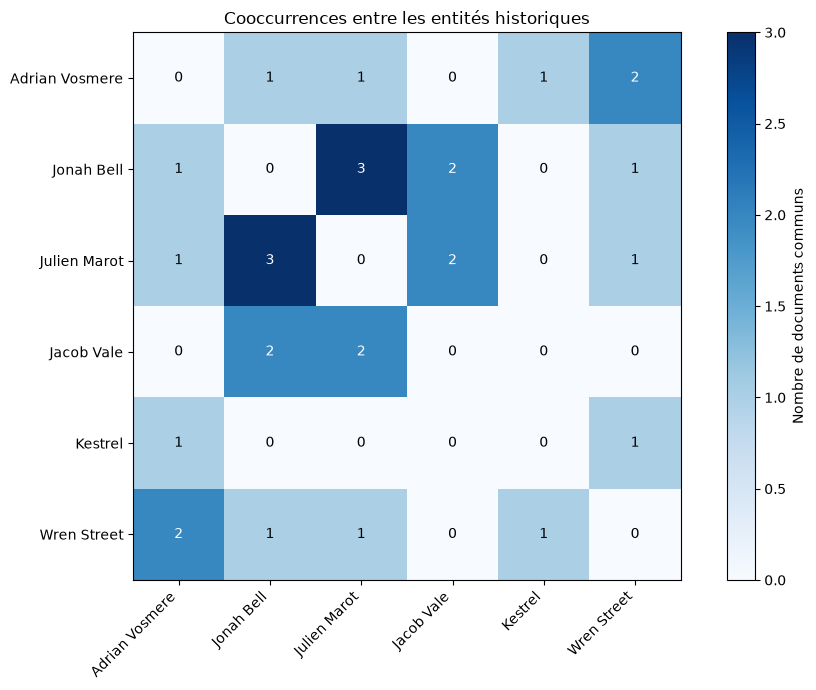

In [79]:
import matplotlib.pyplot as plt
import numpy as np

# Construire une matrice symétrique
matrice = pd.DataFrame(
    0,
    index=entites_presentes,
    columns=entites_presentes
)

for _, ligne in df_cooccurrences.iterrows():
    a = ligne["entite_1"]
    b = ligne["entite_2"]
    n = ligne["nombre_documents_communs"]

    matrice.loc[a, b] = n
    matrice.loc[b, a] = n

# Visualiser la matrice
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(matrice.values, cmap="Blues")

ax.set_xticks(np.arange(len(matrice)))
ax.set_yticks(np.arange(len(matrice)))

ax.set_xticklabels(matrice.columns, rotation=45, ha="right")
ax.set_yticklabels(matrice.index)

# Afficher les valeurs dans les cellules
for i in range(len(matrice)):
    for j in range(len(matrice)):
        ax.text(
            j, i, matrice.iloc[i, j],
            ha="center", va="center",
            color="white" if matrice.iloc[i, j] >= 2 else "black"
        )

plt.colorbar(im, ax=ax, label="Nombre de documents communs")
plt.title("Cooccurrences entre les entités historiques")
plt.tight_layout()
plt.show()

### Interprétation de la carte de chaleur

La carte retrouve surtout les paires Bell–Marot et Vosmere–Wren Street. Nous conservons les identifiants des documents pour relire ces associations.

### 9.13. Identification des documents associés aux principales cooccurrences

Nous retrouvons les textes contenant les principales paires de noms, afin de lire les liens effectivement décrits.


In [80]:
# Examiner les documents des principales cooccurrences

paires_interessantes = [
    ("Jonah Bell", "Julien Marot"),
    ("Jacob Vale", "Jonah Bell"),
    ("Adrian Vosmere", "Wren Street")
]

resultats_documents = []

for a, b in paires_interessantes:

    masque_a = corpus["text"].fillna("").str.contains(
        re.escape(a), case=False, regex=True
    )

    masque_b = corpus["text"].fillna("").str.contains(
        re.escape(b), case=False, regex=True
    )

    documents_communs = corpus[masque_a & masque_b]

    for _, doc in documents_communs.iterrows():
        resultats_documents.append({
            "entite_1": a,
            "entite_2": b,
            "document_id": doc["document_id"]
        })

df_documents_communs = pd.DataFrame(
    resultats_documents,
    columns=["entite_1", "entite_2", "document_id"]
)

# Récupérer les titres des documents
titres_documents = donnees_clean[
    "public_and_investigative_documents"
][["document_id", "title"]]

df_documents_communs = df_documents_communs.merge(
    titres_documents,
    on="document_id",
    how="left"
)

display(df_documents_communs)

,entite_1,entite_2,document_id,title
0,Jonah Bell,Julien Marot,PUB-510033,Extract from the Eastern Orchard Programme Min...
1,Jonah Bell,Julien Marot,PUB-510044,Jacob Vale Identity-Continuity Lead
2,Jonah Bell,Julien Marot,PUB-510076,Catalog Note on Recurrent Historical Identifiers
3,Jacob Vale,Jonah Bell,PUB-510033,Extract from the Eastern Orchard Programme Min...
4,Jacob Vale,Jonah Bell,PUB-510044,Jacob Vale Identity-Continuity Lead
5,Adrian Vosmere,Wren Street,PUB-510043,Letter from the Vosmere Commercial Papers
6,Adrian Vosmere,Wren Street,PUB-510076,Catalog Note on Recurrent Historical Identifiers


### Interprétation des documents associés aux cooccurrences

Bell et Marot sont cités ensemble dans `PUB-510033`, `PUB-510044` et `PUB-510076`. Les autres paires sélectionnées apparaissent dans deux textes. Ces occurrences donnent des sources à examiner, sans établir une identité partagée.


In [81]:
# Examiner les deux documents complémentaires

ids_a_examiner = ["PUB-510033", "PUB-510043"]

documents = donnees_clean["public_and_investigative_documents"]

for doc_id in ids_a_examiner:
    doc = documents.loc[
        documents["document_id"] == doc_id
    ].iloc[0]

    print("\n" + "=" * 60)
    print("Document :", doc_id)
    print("Titre :", doc["title"])
    print("=" * 60)
    print(doc["text"])


Document : PUB-510033
Titre : Extract from the Eastern Orchard Programme Minutes
EXTRACT FROM MINUTES — 18 MAY 1962

Present: Jonah Bell, Julien Marot, Jacob Vale, two representatives of the Agricultural Improvement Board, and the secretary.

Agenda item 3 concerned the eastern orchard programme. Mr. Bell argued that warming trends and expanded flowering corridors would increase the reliability of nocturnal pollination. Mr. Marot requested that cave-access agreements be treated as infrastructure rather than wildlife exceptions. Mr. Vale objected to the proposed industrial concessions, stating that a programme dependent on extraction and permanent heat increase would eventually destroy the habitat it claimed to support.

The meeting agreed to continue trial orchards, seek protection for selected roosts, and postpone public discussion of the associated transport arrangements. Mr. Vale asked that his dissent be entered in full. Mr. Bell replied that continuity required discretion and rep

### Interprétation des documents complémentaires

`PUB-510033` décrit une réunion de 1962 sur les vergers et la pollinisation nocturne. Bell y soutient le programme ; Vale s'oppose aux concessions industrielles et à l'augmentation permanente des températures.

`PUB-510043` évoque l'utilisation de documents Vosmere pour voyager et le fait d'éviter un ancien nom. Une note d'archive rapproche la correspondance de documents liés à Voss. Le contenu des textes donne ainsi plus d'information que le seul partage de noms.

### 9.14. Recherche des thèmes récurrents dans les documents

Nous construisons un dictionnaire manuel de mots-clés pour quatre sujets : pollinisation nocturne, transport et logistique, identités historiques, environnement et habitat. Cette recherche complète la NMF avec des questions choisies après lecture.


In [82]:
# Définir les thèmes et leurs mots-clés associés

themes = {
    "Pollinisation nocturne": [
        "pollination", "pollinator", "nocturnal",
        "orchard", "flowering", "roost"
    ],
    "Transport et logistique": [
        "transport", "shipment", "shipping",
        "route", "logistics", "cold chain"
    ],
    "Identités historiques": [
        "identity", "alias", "historical",
        "signature", "registry", "continuity"
    ],
    "Environnement et habitat": [
        "habitat", "ecological", "conservation",
        "wildlife", "cave", "warming"
    ]
}

# Compter les documents mentionnant chaque thème
resultats_themes = []

for theme, mots in themes.items():

    motif = r"\b(?:" + "|".join(
        re.escape(mot) for mot in mots
    ) + r")\b"

    masque = corpus["text"].fillna("").str.contains(
        motif,
        case=False,
        regex=True
    )

    resultats_themes.append({
        "theme": theme,
        "nombre_documents": int(masque.sum()),
        "pourcentage": round(100 * masque.mean(), 1)
    })

df_themes = pd.DataFrame(resultats_themes)

display(
    df_themes.sort_values(
        "nombre_documents",
        ascending=False
    )
)

,theme,nombre_documents,pourcentage
1,Transport et logistique,40,57.1
2,Identités historiques,15,21.4
3,Environnement et habitat,12,17.1
0,Pollinisation nocturne,1,1.4


### Interprétation des thèmes récurrents

Avec ce dictionnaire, la logistique apparaît dans 40 documents sur 70 (57,1 %), les identités historiques dans 15 (21,4 %), l'environnement dans 12 (17,1 %) et la pollinisation nocturne dans un seul (1,4 %). Un même texte peut appartenir à plusieurs de ces ensembles.


In [83]:
from itertools import combinations

# Construire une matrice de présence des thèmes
presence_themes = pd.DataFrame(index=corpus.index)

for theme, mots in themes.items():

    motif = r"\b(?:" + "|".join(
        re.escape(mot) for mot in mots
    ) + r")\b"

    presence_themes[theme] = corpus["text"].fillna("").str.contains(
        motif,
        case=False,
        regex=True
    )

# Calculer les documents communs entre chaque paire de thèmes
resultats_cooccurrences_themes = []

for theme_a, theme_b in combinations(themes.keys(), 2):

    nombre = (
        presence_themes[theme_a] &
        presence_themes[theme_b]
    ).sum()

    resultats_cooccurrences_themes.append({
        "theme_1": theme_a,
        "theme_2": theme_b,
        "nombre_documents_communs": int(nombre)
    })

df_cooccurrences_themes = pd.DataFrame(
    resultats_cooccurrences_themes
).sort_values(
    "nombre_documents_communs",
    ascending=False
)


### 9.15. Comparer les thèmes avec Jaccard

Nous repérons les thèmes par un dictionnaire de mots-clés choisi manuellement.
Jaccard divise le nombre de documents communs par le nombre de documents qui
mentionnent au moins un des deux thèmes. Ce calcul complète les effectifs.


In [84]:
# Calculer le coefficient de Jaccard entre les thèmes

resultats_jaccard = []

for theme_a, theme_b in combinations(themes.keys(), 2):

    a = presence_themes[theme_a]
    b = presence_themes[theme_b]

    intersection = (a & b).sum()
    union = (a | b).sum()

    jaccard = intersection / union if union > 0 else 0

    resultats_jaccard.append({
        "theme_1": theme_a,
        "theme_2": theme_b,
        "documents_communs": int(intersection),
        "jaccard": round(jaccard, 3)
    })

df_jaccard = pd.DataFrame(resultats_jaccard)

display(
    df_jaccard.sort_values("jaccard", ascending=False)
)

,theme_1,theme_2,documents_communs,jaccard
5,Identités historiques,Environnement et habitat,6,0.286
3,Transport et logistique,Identités historiques,7,0.146
2,Pollinisation nocturne,Environnement et habitat,1,0.083
4,Transport et logistique,Environnement et habitat,4,0.083
1,Pollinisation nocturne,Identités historiques,1,0.067
0,Pollinisation nocturne,Transport et logistique,1,0.025


### Interprétation des coefficients de Jaccard

Identités et environnement ont le Jaccard le plus élevé : 0,286 pour six documents communs. Transport et identités partagent sept textes, mais leur union est plus grande : leur Jaccard vaut 0,146. Les scores dépendent du dictionnaire de mots retenu.

### 9.16. Identification des documents associés aux thèmes historiques et environnementaux

Nous lisons les six documents qui associent les mots-clés historiques et environnementaux.


In [85]:
# Documents mentionnant les deux thèmes
masque = (
    presence_themes["Identités historiques"] &
    presence_themes["Environnement et habitat"]
)

documents_selectionnes = corpus.loc[
    masque, ["document_id", "text"]
].copy()

# Récupérer les titres disponibles
titres = donnees_clean[
    "public_and_investigative_documents"
][["document_id", "title"]]

documents_selectionnes = documents_selectionnes.merge(
    titres,
    on="document_id",
    how="left"
)

display(
    documents_selectionnes[
        ["document_id", "title"]
    ]
)


,document_id,title
0,PUB-510094,Opposed Ecological Strategies and Disclosure
1,PUB-510033,Extract from the Eastern Orchard Programme Min...
2,PUB-510044,Jacob Vale Identity-Continuity Lead
3,PUB-510079,Message Concerning Collected Eonycteris
4,PUB-510076,Catalog Note on Recurrent Historical Identifiers
5,PUB-510001,Historical Meeting Extract 112


### Interprétation des documents associés aux thèmes

La sélection retrouve `PUB-510033`, `PUB-510044` et `PUB-510076`, déjà lus, ainsi que `PUB-510094`, `PUB-510079` et `PUB-510001`.


In [86]:
# Examiner les documents complémentaires

ids_a_examiner = [
    "PUB-510094",
    "PUB-510079",
    "PUB-510001"
]

documents = donnees_clean["public_and_investigative_documents"]

for doc_id in ids_a_examiner:

    doc = documents.loc[
        documents["document_id"] == doc_id
    ].iloc[0]

    print("\n" + "=" * 60)
    print("Document :", doc_id)
    print("Titre :", doc["title"])
    print("=" * 60)

    print(doc["text"])


Document : PUB-510094
Titre : Opposed Ecological Strategies and Disclosure
QUESTION
Why do two groups using similar ecological language recommend sharply different forms of action?

METHOD
Public statements, campaign material, institutional memoranda, and research correspondence were coded for references to extraction, emissions, habitat thresholds, disclosure, and institutional control. The analysis focused on repeated phrases rather than individual names.

FINDINGS
One cluster argues that industrial extraction and warming must be reduced because ecological thresholds are being crossed. It favors public records, independent monitoring, and broad accountability. A second cluster also discusses ecological protection but repeatedly couples it with controlled access, continuity of selected programmes, and warnings that unrestricted disclosure could produce instability. The two clusters sometimes use the same evidence while proposing opposite governance responses.

Several documents assoc

### Interprétation des documents complémentaires

`PUB-510094` oppose deux orientations : réduire l'extraction et ouvrir l'information, ou maintenir certains programmes avec des accès contrôlés. Le vocabulaire partagé ne signifie donc pas toujours un accord entre acteurs.

`PUB-510079` relie le témoignage sur les Eonycteris aux unités scellées et aux ajustements. `PUB-510001` apporte un contexte historique sur le financement et le transport, avec des lacunes documentaires.

## 10. Vérification croisée des indices

Le témoignage `PUB-510079` évoque un accès printanier à Kestrel, du stockage frigorifique et des ajustements. Nous comparons ces indications aux dossiers administratifs.

### 10.1. Recherche des demandes d'accès au site Kestrel

Nous sélectionnons les dossiers `KNT-KES` et regardons leurs dates, motifs, équipements et organisation demandeuse.


In [87]:
dossiers_kestrel = df_dossiers[df_dossiers["site_code"] == "KNT-KES"].copy()
dossiers_kestrel["mois"] = dossiers_kestrel["date_debut"].dt.month
display(dossiers_kestrel[[
    "access_case_number", "date_debut", "access_purpose", "equipment_category"
]].sort_values("date_debut"))


,access_case_number,date_debut,access_purpose,equipment_category
8,ACC-2018-0002,2018-02-19 09:00:00,night wildlife monitoring programme,portable monitoring and cold-storage equipment
26,ACC-2021-0009,2021-02-22 09:00:00,acoustic monitoring and equipment maintenance,protective field equipment
50,ACC-2024-0014,2024-02-19 09:00:00,night wildlife monitoring programme,acoustic and camera equipment


### Interprétation des demandes d'accès au site Kestrel

Les trois demandes de Kestrel viennent d'Horizon et ont été créées en février 2018, 2021 et 2024. Deux déclarent de la surveillance nocturne, la troisième de la maintenance acoustique. Celle de 2018 mentionne du stockage frigorifique.

### 10.2. Vérification des dates effectives d'accès

La création d'un dossier ne donne pas la date d'intervention. Nous utilisons les événements `access_started` et `access_completed`.


In [88]:
# Vérifier les dates effectives des accès à Kestrel

evenements_kestrel = donnees_clean[
    "site_access_case_events"
].copy()

evenements_kestrel = evenements_kestrel[
    (evenements_kestrel["site_code"] == "KNT-KES") &
    (evenements_kestrel["activity"].isin([
        "access_started",
        "access_completed"
    ]))
]

display(
    evenements_kestrel[
        [
            "access_case_number",
            "event_time",
            "activity",
            "requesting_organization_name"
        ]
    ].sort_values(
        ["access_case_number", "event_time"]
    )
)

,access_case_number,event_time,activity,requesting_organization_name
13,ACC-2018-0002,2018-03-22 18:00:00,access_started,Horizon Field Research Cooperative
14,ACC-2018-0002,2018-03-23 03:00:00,access_completed,Horizon Field Research Cooperative
67,ACC-2021-0009,2021-03-25 18:00:00,access_started,Horizon Field Research Cooperative
68,ACC-2021-0009,2021-03-26 03:00:00,access_completed,Horizon Field Research Cooperative
108,ACC-2024-0014,2024-03-21 18:00:00,access_started,Horizon Field Research Cooperative
109,ACC-2024-0014,2024-03-22 03:00:00,access_completed,Horizon Field Research Cooperative


### Interprétation des dates d'intervention

Les interventions ont lieu du 22 au 23 mars 2018, du 25 au 26 mars 2021 et du 21 au 22 mars 2024. Elles commencent à 18 h et se terminent à 3 h, soit neuf heures, avec trois ans entre les années d'intervention.

Le mois correspond à l'indication printanière du témoignage, qui ne donne pas d'année précise.

### 10.3. Comparaison des parcours administratifs à Kestrel

Nous comparons aussi les étapes et les délais de ces trois dossiers.


In [89]:
dossiers_kestrel_ids = dossiers_kestrel["access_case_number"].tolist()
parcours_kestrel = donnees_clean["site_access_case_events"]
parcours_kestrel = parcours_kestrel[parcours_kestrel["access_case_number"].isin(dossiers_kestrel_ids)].copy()
dates_kestrel = parcours_kestrel.pivot_table(
    index="access_case_number", columns="activity", values="event_time", aggfunc="min"
)
bilan_kestrel = pd.DataFrame({
    "Événements": parcours_kestrel.groupby("access_case_number").size(),
    "Examen sécurité": parcours_kestrel["activity"].eq("security_review").groupby(parcours_kestrel["access_case_number"]).any(),
    "Autorisation → accès (jours)": (dates_kestrel["access_started"] - dates_kestrel["authorization_granted"]).dt.total_seconds() / 86400,
    "Fin accès → clôture (jours)": (dates_kestrel["closure_recorded"] - dates_kestrel["access_completed"]).dt.total_seconds() / 86400
})
display(bilan_kestrel.round(2))


,Événements,Examen sécurité,Autorisation → accès (jours),Fin accès → clôture (jours)
access_case_number,,,,
ACC-2018-0002,8,True,10.38,2.33
ACC-2021-0009,8,True,10.38,2.33
ACC-2024-0014,7,False,10.38,2.33


### Interprétation des parcours administratifs

Les dossiers de 2018 et 2021 ont huit événements, celui de 2024 en a sept sans examen de sécurité enregistré. Les accès commencent dix jours après l'autorisation et les dossiers sont clôturés environ deux jours après la fin de l'intervention.

### 10.4. Bilan du croisement des indices

Les registres confirment des accès nocturnes printaniers par Horizon et la présence déclarée d'un équipement frigorifique dans un dossier. Ces éléments rejoignent le contexte du témoignage. La collecte d'Eonycteris et la destination des unités ne sont pas décrites par ces dossiers.

### 10.5. Dossiers réglementaires et expéditions citées

Nous joignons les expéditions aux mémos et aux dossiers par leur numéro. La comparaison des dates porte seulement sur les dossiers citant une expédition présente dans le fichier.


In [90]:
logistique = nettoyer_espaces(pd.read_csv(racine / "data/logistics/shipments.csv")).drop_duplicates()
logistique["declared_purpose"] = logistique["declared_purpose"].str.lower()
for col in ["dispatch_time", "arrival_time"]:
    logistique[col] = convertir_dates(logistique[col])

reg = donnees_clean["regulatory_case_events"].copy()
memos = donnees_clean["institutional_memos"].copy()
motif_env = "environmental and wildlife reference materials"
expeditions_env = logistique[logistique["declared_purpose"].eq(motif_env)]
references_public = set(reg["related_shipment_number"].dropna()) | set(memos["related_shipment_number"].dropna())
communes = expeditions_env[expeditions_env["shipment_number"].isin(references_public)]
numeros_communs = set(communes["shipment_number"])
dossiers_communs = reg[reg["related_shipment_number"].isin(numeros_communs)].drop_duplicates("case_number")
memos_communs = memos[memos["related_shipment_number"].isin(numeros_communs)]

print("Expéditions environnementales :", expeditions_env["shipment_number"].nunique())
print("Expéditions citées dans les données publiques :", communes["shipment_number"].nunique())
print("Dossiers réglementaires associés :", len(dossiers_communs))
print("Mémos associés :", len(memos_communs))


Expéditions environnementales : 18
Expéditions citées dans les données publiques : 10
Dossiers réglementaires associés : 11
Mémos associés : 1


In [91]:
# Dates d'ouverture des dossiers réglementaires
ouvertures = reg[
    reg["activity"] == "case_opened"
][
    ["case_number", "related_shipment_number", "event_time"]
].dropna(subset=["related_shipment_number"]).copy()

ouvertures = ouvertures.drop_duplicates("case_number")

# Dates de clôture
clotures = reg[
    reg["activity"] == "case_closed"
][
    ["case_number", "event_time"]
].copy()

clotures["event_time"] = pd.to_datetime(
    clotures["event_time"], errors="coerce"
)

clotures = (
    clotures.groupby("case_number", as_index=False)["event_time"]
    .max()
    .rename(columns={"event_time": "date_cloture"})
)

# Jointure avec les expéditions logistiques
chronologie = ouvertures.merge(
    logistique[
        ["shipment_number", "dispatch_time", "declared_purpose"]
    ].drop_duplicates("shipment_number"),
    left_on="related_shipment_number",
    right_on="shipment_number",
    how="inner",
    validate="many_to_one"
)

chronologie = chronologie.merge(
    clotures,
    on="case_number",
    how="left"
)

# Conversion des dates
chronologie["event_time"] = pd.to_datetime(
    chronologie["event_time"], errors="coerce"
)

chronologie["dispatch_time"] = pd.to_datetime(
    chronologie["dispatch_time"], errors="coerce"
)

# Ouverture avant le départ
chronologie["ouverture_avant_depart"] = (
    chronologie["event_time"] <
    chronologie["dispatch_time"]
)

# Clôture avant le départ
chronologie["cloture_avant_depart"] = (
    chronologie["date_cloture"] <
    chronologie["dispatch_time"]
)

# Écart entre ouverture et départ
chronologie["ecart_jours"] = (
    chronologie["dispatch_time"] -
    chronologie["event_time"]
).dt.days

# Identification des flux
chronologie["type_flux"] = np.where(
    chronologie["declared_purpose"].astype("string")
    .str.strip().str.lower() == motif_env,
    "Environnemental",
    "Autres"
)

# Comparaison entre les deux groupes
comparaison = (
    chronologie.groupby("type_flux")
    .agg(
        total_dossiers=("case_number", "nunique"),
        ouvertures_anticipees=("ouverture_avant_depart", "sum"),
        clotures_anticipees=("cloture_avant_depart", "sum")
    )
)

comparaison["pourcentage_ouverture"] = (
    comparaison["ouvertures_anticipees"]
    / comparaison["total_dossiers"] * 100
).round(2)

comparaison["pourcentage_cloture"] = (
    comparaison["clotures_anticipees"]
    / comparaison["total_dossiers"] * 100
).round(2)

print("COMPARAISON DES FLUX")
display(comparaison)


COMPARAISON DES FLUX


,total_dossiers,ouvertures_anticipees,clotures_anticipees,pourcentage_ouverture,pourcentage_cloture
type_flux,,,,,
Autres,4,1,1,25.00,25.00
Environnemental,11,6,3,54.55,27.27


In [92]:
# Dossiers environnementaux clôturés avant
# le départ des expéditions associées

clotures_avant_depart = chronologie[
    (chronologie["type_flux"] == "Environnemental") &
    (chronologie["cloture_avant_depart"])
].copy()

print(
    "Nombre de dossiers environnementaux clôturés avant départ :",
    len(clotures_avant_depart)
)

display(
    clotures_avant_depart[
        [
            "case_number",
            "shipment_number",
            "event_time",
            "date_cloture",
            "dispatch_time",
            "ecart_jours"
        ]
    ].sort_values("ecart_jours", ascending=False)
)

Nombre de dossiers environnementaux clôturés avant départ : 3


,case_number,shipment_number,event_time,date_cloture,dispatch_time,ecart_jours
6,REG-2022-0007,SHP-2023-00071,2022-10-23 09:00:00,2022-11-14 09:00:00,2023-11-10 09:00:00,383
7,REG-2023-0008,SHP-2024-00007,2023-04-10 09:00:00,2023-04-29 09:00:00,2024-03-22 09:00:00,347
9,REG-2025-0010,SHP-2025-00005,2025-02-03 09:00:00,2025-02-25 09:00:00,2025-04-18 09:00:00,74


Quinze dossiers ont une expédition correspondante : onze pour le flux environnemental et quatre pour les autres. Trois sont clôturés avant le départ dans le premier groupe (27,3 %), contre un dans le second (25 %). Le décalage n'est donc pas spécifique au flux environnemental dans ces données.

### 10.6. Retrouver les bénéficiaires de MRP-42 dans les registres publics

Health distingue dix patients au profil physiologique atypique et huit bénéficiaires de MRP-42 sous autorisation `restricted_specialist`. Nous reprenons le second groupe à partir des procédures et cherchons leurs noms et fonctions dans les registres publics.


In [93]:
patients_sante = nettoyer_espaces(pd.read_csv(racine / "data/health/patient_administration.csv")).drop_duplicates()
procedures_sante = nettoyer_espaces(pd.read_csv(racine / "data/health/clinical_procedures.csv")).drop_duplicates()
consultations_sante = nettoyer_espaces(pd.read_csv(racine / "data/health/clinical_encounters.csv")).drop_duplicates()
patients_sante["date_of_birth"] = convertir_dates(patients_sante["date_of_birth"])
procedures_sante["performed_time"] = convertir_dates(procedures_sante["performed_time"])
procedures_sante["authorization_class"] = procedures_sante["authorization_class"].str.lower()
mrp_sante = procedures_sante[procedures_sante["procedure_code"].eq("MRP-42")].copy()
mrp_restreint = mrp_sante[mrp_sante["authorization_class"].eq("restricted_specialist")]
nombre_mrp = mrp_restreint.groupby("patient_number").size().reset_index(name="nb_MRP42")
beneficiaires = patients_sante.merge(nombre_mrp, on="patient_number", validate="one_to_one")
beneficiaires["nom"] = beneficiaires["given_name"] + " " + beneficiaires["family_name"]

postes_publics = donnees_clean["public_appointments"][["office_holder_name", "office_title"]].rename(
    columns={"office_holder_name": "nom", "office_title": "fonction_publique"})
postes_publics["source_registre"] = "Nominations publiques"
postes_societes = df_dirigeants[["full_name", "role_title"]].rename(
    columns={"full_name": "nom", "role_title": "fonction_publique"})
postes_societes["source_registre"] = "Mandats de sociétés"
postes = pd.concat([postes_publics, postes_societes], ignore_index=True).drop_duplicates()
liens_patients = beneficiaires.merge(postes, on="nom", how="left", validate="one_to_many")
roles_identiques = liens_patients["occupation_text"].str.casefold().eq(liens_patients["fonction_publique"].str.casefold())
beneficiaires_publics = liens_patients[roles_identiques].drop_duplicates("patient_number")
display(beneficiaires_publics[["patient_number", "nom", "nb_MRP42", "fonction_publique", "source_registre"]])


,patient_number,nom,nb_MRP42,fonction_publique,source_registre
0,PAT-31221,Leora Kassen,5,Head of government of Kintara Republic,Nominations publiques
3,PAT-31044,Tavian Serat,4,Senior minister of the Avelora Federation,Nominations publiques
6,PAT-31174,Mirek Talven,4,Regional governor in the Tembara Commonwealth,Nominations publiques
9,PAT-31119,Celene Varro,4,Chief executive of Solvane Energy Group,Mandats de sociétés
12,PAT-31074,Oskar Nivren,4,Executive chair of Nivren Maritime Logistics,Mandats de sociétés
15,PAT-31183,Adrienne Solva,3,Executive director of Ardena Capital Union,Mandats de sociétés
19,PAT-31142,Rayan Belen,3,Chair of Belen Agro-Industries,Mandats de sociétés
21,PAT-31099,Elira Vaun,3,Retired political intermediary and former coun...,Nominations publiques


Les huit bénéficiaires sont retrouvés avec le même nom et une fonction identique. Ils reçoivent 30 procédures restreintes au total. `PUB-510045` décrit aussi huit responsables suivis régulièrement, sans les nommer.

Les numéros de licence permettent ensuite de vérifier le médecin, les établissements et leur gestionnaire.


In [94]:
prestataires_mrp = mrp_restreint[["performing_license_number", "performing_facility_license"]].drop_duplicates()
prestataires_mrp = prestataires_mrp.merge(
    donnees_clean["licensed_professionals"][["license_number", "professional_name"]],
    left_on="performing_license_number", right_on="license_number", how="left", validate="many_to_one")
prestataires_mrp = prestataires_mrp.merge(
    donnees_clean["licensed_facilities"][["facility_license_number", "facility_name", "operating_organization_registration"]],
    left_on="performing_facility_license", right_on="facility_license_number", how="left", validate="many_to_one")
prestataires_mrp = prestataires_mrp.merge(
    donnees_clean["registered_entities"][["registration_number", "legal_name"]],
    left_on="operating_organization_registration", right_on="registration_number", how="left", validate="many_to_one")
display(prestataires_mrp[["performing_license_number", "professional_name", "performing_facility_license", "facility_name", "legal_name"]])


,performing_license_number,professional_name,performing_facility_license,facility_name,legal_name
0,LIC-VLN-MED-1002,Dr. Naima Orrel,FAC-VLN-101,Asterion Central Clinical Campus,Asterion Clinical Institute
1,LIC-VLN-MED-1002,Dr. Naima Orrel,FAC-AVL-201,Asterion Avelora Executive Clinic,Asterion Clinical Institute


Les 30 procédures sont réalisées par le même médecin, Dr. Naima Orrel (`LIC-VLN-MED-1002`), dans les deux cliniques Asterion. Les licences et les gestionnaires concordent entre les sources.

### 10.7. Examiner les deux hypothèses d'identité d'Elias Voss

La partie Health signale deux candidats : `PAT-31065`, cité dans la note clinique `CLN-510025`, et `PAT-31162`, dont l'année de naissance est plus proche du registre. Nous comparons leurs attributs sans leur attribuer une identité publique.


In [95]:
candidats_voss = patients_sante[patients_sante["patient_number"].isin(["PAT-31065", "PAT-31162"])].copy()
candidats_voss["nom"] = candidats_voss["given_name"] + " " + candidats_voss["family_name"]
candidats_voss["annee_naissance"] = candidats_voss["date_of_birth"].dt.year
adressages = consultations_sante[consultations_sante["referral_source"].str.lower().eq("executive health office")].groupby("patient_number").size()
candidats_voss["adressages_executive"] = candidats_voss["patient_number"].map(adressages).fillna(0).astype(int)
display(candidats_voss[["patient_number", "nom", "annee_naissance", "home_region", "occupation_text", "adressages_executive"]])

voss_public = df_dirigeants[df_dirigeants["full_name"].eq("Dr. Elias Voss")]
display(voss_public[["full_name", "birth_year_or_age_band", "nationality_or_region", "role_title", "appointment_date"]])


,patient_number,nom,annee_naissance,home_region,occupation_text,adressages_executive
0,PAT-31162,Eli Varen,1962,Valenne Republic,corporate adviser,1
6,PAT-31065,Corin Hallen,1975,Valenne Republic,clinical specialist,1


,full_name,birth_year_or_age_band,nationality_or_region,role_title,appointment_date
3,Dr. Elias Voss,1961,Valennan,Executive chair of Meridian BioLogistics,1996-01-01


Le registre situe la naissance d'Elias Voss en 1961. `PAT-31065` est né en 1975 et est déclaré spécialiste clinique ; `PAT-31162` est né en 1962 et est déclaré conseiller d'entreprise en région Valenne. Les deux patients ont un adressage par `executive health office`.

Le premier candidat suit l'indication de la note, tandis que le second présente des attributs plus proches du registre. Aucune des deux identités n'est établie.

### 10.8. Relier les établissements publics aux sites logistiques

Les codes de licence `FAC-…` et les codes ERP `FCL-…` sont différents. Nous rapprochons les organismes par leur numéro d'enregistrement, puis les établissements par leurs coordonnées exactes **et** leur organisme gestionnaire.


In [96]:
partenaires_log = nettoyer_espaces(pd.read_csv(racine / "data/logistics/erp_business_partners.csv")).drop_duplicates()
sites_log = nettoyer_espaces(pd.read_csv(racine / "data/logistics/erp_facilities.csv")).drop_duplicates()
partenaires_enregistres = partenaires_log.dropna(subset=["external_registration_number"])
pont_organisations = donnees_clean["registered_entities"].merge(
    partenaires_enregistres[["partner_code", "external_registration_number"]],
    left_on="registration_number", right_on="external_registration_number", how="left", validate="one_to_one")

codes_organismes = partenaires_log.set_index("partner_code")["external_registration_number"]
sites_log["operating_organization_registration"] = sites_log["operating_partner_code"].map(codes_organismes)
pont_etablissements = donnees_clean["licensed_facilities"].merge(
    sites_log[["facility_code", "latitude", "longitude", "operating_organization_registration"]],
    on=["latitude", "longitude", "operating_organization_registration"], how="left", validate="one_to_one")
display(pont_etablissements[["facility_license_number", "facility_code", "facility_name", "operating_organization_registration"]])


,facility_license_number,facility_code,facility_name,operating_organization_registration
0,FAC-VLN-101,FCL-1010,Asterion Central Clinical Campus,REG-VLN-01002
1,FAC-AVL-201,FCL-1007,Asterion Avelora Executive Clinic,REG-VLN-01002
2,FAC-AVL-301,FCL-1015,Threshold Earth Avelora Laboratory,REG-AVL-01007


Les trois établissements ont une correspondance ERP : les deux cliniques Asterion (`FAC-VLN-101` ↔ `FCL-1010`, `FAC-AVL-201` ↔ `FCL-1007`) et le laboratoire Threshold Earth (`FAC-AVL-301` ↔ `FCL-1015`). Les 24 organismes de `registered_entities` ont aussi une correspondance ERP.

Nous reprenons le rapprochement temporel de la partie logistique : une procédure MRP-42 a-t-elle lieu sur le même site après une livraison clinique ? Nous comparons des fenêtres de 7, 14 et 30 jours pour rendre visible l'effet de ce choix.


In [97]:
livraisons_cliniques = logistique[logistique["declared_purpose"].eq("temperature-controlled clinical programme delivery")].copy()
livraisons_cliniques = livraisons_cliniques.merge(
    pont_etablissements[["facility_code", "facility_license_number"]],
    left_on="destination_facility_code", right_on="facility_code", how="left", validate="many_to_one")
paires_cliniques = livraisons_cliniques[["shipment_number", "arrival_time", "facility_license_number"]].merge(
    mrp_sante[["procedure_record_id", "performed_time", "performing_facility_license"]],
    left_on="facility_license_number", right_on="performing_facility_license", validate="many_to_many")
paires_cliniques["delai_jours"] = (paires_cliniques["performed_time"] - paires_cliniques["arrival_time"]).dt.total_seconds() / 86400

resume_fenetres = []
for jours in [7, 14, 30]:
    proches = paires_cliniques[paires_cliniques["delai_jours"].between(0, jours)]
    resume_fenetres.append({"fenetre_jours": jours,
        "livraisons_avec_MRP42": proches["shipment_number"].nunique(),
        "procedures_MRP42": proches["procedure_record_id"].nunique()})
display(pd.DataFrame(resume_fenetres))


,fenetre_jours,livraisons_avec_MRP42,procedures_MRP42
0,7,20,20
1,14,26,27
2,30,26,28


Sur 26 livraisons cliniques, 20 sont suivies d'une procédure MRP-42 sous 7 jours, et les 26 sous 14 jours. La fenêtre de 30 jours retrouve 28 réalisations distinctes de MRP-42. Ce sont des rapprochements de dates et de sites : ils ne permettent pas de suivre le contenu d'un lot jusqu'à un patient.

### 10.9. Retrouver les expéditions citées dans les mémos CHAMELEO

Nous revenons aux mémos mentionnant CHAMELEO ou Unwabu, repérés dans l'analyse textuelle. Leur référence d'expédition fournit une clé directe vers les données logistiques.


In [98]:
mentions_chameleo = donnees_clean["institutional_memos"][
    donnees_clean["institutional_memos"]["text"].str.contains(r"\b(?:CHAMELEO|Unwabu)\b", case=False, na=False)
].copy()
memos_chameleo = mentions_chameleo.dropna(subset=["related_shipment_number"])
liens_chameleo = memos_chameleo.merge(logistique,
    left_on="related_shipment_number", right_on="shipment_number", how="left", validate="many_to_one")
print("Mémos mentionnant le terme :", mentions_chameleo["document_id"].tolist())
display(liens_chameleo[["document_id", "document_date", "related_shipment_number", "authorization_class", "declared_purpose"]])


Mémos mentionnant le terme : ['MEM-510100', 'MEM-510101', 'MEM-510089']


,document_id,document_date,related_shipment_number,authorization_class,declared_purpose
0,MEM-510100,2023-08-17,SHP-2022-00011,ordinary,agricultural distribution
1,MEM-510101,2025-03-14,SHP-2023-00035,ordinary,facility replenishment


`MEM-510100` cite `SHP-2022-00011` et `MEM-510101` cite `SHP-2023-00035`. Les deux expéditions existent dans le CSV et portent une autorisation `ordinary`. Les mémos décrivent, eux, une procédure de traitement sécurisé et des annexes restreintes.

`MEM-510089` mentionne aussi CHAMELEO, mais pour désigner un ancien tableau de conformité abandonné. Il ne cite aucune expédition et n'est pas retenu comme preuve d'un lien avec les livraisons sécurisées.

Les deux premiers mémos précisent un lien administratif entre CHAMELEO, Unwabu et Meridian. Ils ne précisent pas le contenu réel des expéditions.

## 11. Synthèse de l'enquête

### Résultats dans les registres publics

- Les 60 dossiers d'accès comprennent 18 dossiers Horizon. Douze comportent un examen de sécurité, contre aucun des 42 autres dossiers.
- L'IQR repère cinq dossiers au nombre d'étapes inhabituel. Trois concernent Horizon, avec un refus suivi d'une nouvelle demande : l'examen du parcours explique leur longueur.
- Après exclusion des neuf durées négatives, le z-score modifié signale six mandats de 34 à 49 ans parmi 49 mandats terminés aux dates cohérentes.
- Le graphe des 27 dirigeants multi-organisations comporte trois composantes. Ces liens décrivent des fonctions administratives, sans établir des opérations communes.
- Les trois accès de Horizon Field Research Cooperative à Kestrel se déroulent en mars 2018, 2021 et 2024, de 18 h à 3 h. Ces interventions peuvent être rapprochées du témoignage `PUB-510079`, qui évoque la collecte d'*Eonycteris spelaea*, une espèce de chauve-souris frugivore, ainsi qu'une possible utilisation à des fins de consommation.
- Les cooccurrences et la lecture des documents suggèrent des continuités entre certaines identités historiques et des stratégies environnementales opposées. Les chaînes de noms ont été choisies comme hypothèses documentaires ; elles ne démontrent pas une identité commune.

### Ce qu'apportent les croisements

**Santé.** Les huit bénéficiaires de MRP-42 en mode `restricted_specialist` sont retrouvés dans les registres avec les mêmes noms et fonctions. Les 30 procédures sont réalisées par Dr. Naima Orrel dans les deux cliniques Asterion. Le document `PUB-510045` décrit un groupe de responsables suivis médicalement de manière répétée. Ce rapprochement concerne le groupe MRP-42, distinct des dix patients au profil physiologique atypique.

**Identité d'Elias Voss.** La note clinique oriente vers `PAT-31065`, mais son année de naissance et son métier correspondent mal au registre. `PAT-31162` présente des attributs plus proches. Les deux hypothèses restent ouvertes.

**Logistique.** Les licences publiques correspondent aux trois sites ERP concernés. Les 26 livraisons cliniques vers Asterion sont suivies de MRP-42 sur le même site sous 14 jours. Le lien porte sur les dates et les lieux, pas sur le contenu d'un lot. Deux mémos CHAMELEO citent également des expéditions présentes dans le fichier.

Le croisement réglementaire retrouve 11 dossiers associés au flux environnemental. Trois sont clôturés avant le départ, contre un parmi les quatre autres dossiers : ces proportions proches ne montrent pas une spécificité de ce flux.

### Hypothèses retenues

Une première piste relie les accès Horizon, les flux biologiques et les témoignages sur les unités scellées. Une seconde relie les approvisionnements cliniques de Meridian, les établissements Asterion et la procédure MRP-42, dont l’usage `restricted_specialist` concerne huit responsables. Les documents CHAMELEO ajoutent un lien de gouvernance et de traitement des dossiers.

Ces résultats ne démontrent ni l'utilisation finale des spécimens, ni un effet du traitement, ni une identité commune entre les personnes historiques. Ils donnent des relations précises à discuter entre les trois parties du projet.
